# **Zomato Restaurant Clustering & Sentiment Analysis**

##### **Project Type**    - Unsupervised ML (Clustering) with NLP-based sentiment features
##### **Contribution**    - Individual
##### **Team Member 1 -** Sk Alauddin

# **Project Summary -**

Zomato is an Indian restaurant aggregator that lists restaurants, menus, prices and customer reviews. This project analyses two Zomato files for Hyderabad: a *metadata* table of 105 restaurants (cost for two, cuisines, Zomato collection tags, timings) and a *review* table of 10,000 customer reviews (rating, review text, reviewer followers, pictures posted, time). The goal is to (1) understand what drives ratings and customer behaviour, (2) turn the review text into a sentiment signal, and (3) cluster the restaurants into a small number of **actionable segments** that Zomato and restaurant owners can treat differently.

**Data preparation.** Costs were converted from text ("1,300") to numbers, 36 duplicate reviews and 38 rows without a rating were removed, reviewer metadata ("12 Reviews , 206 Followers") was parsed into numbers, timings were converted to daily opening hours, and Zomato collection tags and cuisines were counted and one-hot encoded. Five restaurants have no reviews, so 100 restaurants were clustered. Right-skewed variables (cost, followers, pictures) were log-transformed and winsorised instead of deleted, because the expensive and heavily reviewed restaurants are genuine, not errors.

**EDA and hypotheses.** Fifteen charts follow the Univariate-Bivariate-Multivariate (UBM) rule. Key findings: 63% of reviews are 4-5 stars but 24% are 1-2 stars; the median meal for two costs Rs 700; North Indian and Chinese dominate the market; weekend and 9-11 pm are peak review times; reviews with pictures are more positive (3.86 vs 3.54 stars). Three hypothesis tests (Spearman correlation, Mann-Whitney U, Kruskal-Wallis) showed that more expensive restaurants are rated higher (rho = 0.38, p = 0.0001), that reviews with pictures carry higher ratings (p = 0.003), and that ratings differ across budget, mid-range and premium tiers (p = 0.0001).

**Text mining and sentiment.** Reviews were cleaned (contractions, punctuation, URLs, stop-words with negations preserved, slang normalisation, lemmatisation) and vectorised with TF-IDF. A Logistic Regression sentiment model (class-weighted for the imbalance, 80.3% hold-out accuracy, 5-fold out-of-fold predictions for scoring) produced a per-restaurant sentiment score that agrees closely with the average star rating (r = 0.97), which validates both signals.

**Clustering.** Five interpretable features (log cost, average rating, reviewer reach, pictures per review, number of Zomato collections) were standardised and clustered with three algorithms: K-Means, Hierarchical (Ward / dendrogram) and Gaussian Mixture. k was chosen with elbow charts, silhouette scores and dendrograms, hyper-parameters were grid-searched, and stability was checked with a bootstrap (ARI = 0.76). All three algorithms recover the same three-tier structure; the tuned Gaussian Mixture was selected (silhouette 0.282, Davies-Bouldin 1.196, Calinski-Harabasz 40.2).

**Segments and strategy.** (1) *Premium crowd-pleasers* (13 restaurants, about Rs 1,350, 4.34 stars, 10% negative reviews) - protect and promote; (2) *Buzzy mid-premium* (34, about Rs 1,190, 3.70 stars, influential reviewers, long photo-rich reviews, 19% negative) - fix consistency while they are in the spotlight; (3) *Budget quick-service* (53, about Rs 550, 3.36 stars, 32% negative, few collection tags) - raise quality and visibility through delivery and value offers. The model is saved with joblib and can place a new restaurant into a segment. Limitations: one city, 100 reviews per restaurant, 100 data points and moderate silhouette values, meaning the segments are overlapping tiers rather than isolated islands.

# **GitHub Link -**

https://github.com/DatagenieSK/Zomato_Restaurant_Clustering.git


# **Problem Statement**

**Segment Zomato restaurants into meaningful groups using their cost, cuisines, collections, timings and customer-review behaviour, and analyse customer sentiment, so that (a) customers can find the right kind of restaurant and (b) Zomato and restaurant owners know which segments to promote, fix or grow.**

Business questions answered in this notebook:
1. How are cost, rating and cuisines related? (Is cost correlated to rating?)
2. What do happy and unhappy customers talk about?
3. Which restaurants form natural segments, how many segments are there, and what should the company do for each?

# **General Guidelines** : -

1. The notebook is fully executable top-to-bottom in one go (a fixed random seed is used everywhere); the only requirement is to upload the two CSV files to the Colab *Files* panel.
2. Every logic block is commented; every chart answers the three standard questions (why this chart, insight, business impact).
3. The Univariate / Bivariate / Multivariate ("UBM") order is followed for the 15 charts.
4. Every algorithm is explained, evaluated, cross-validated (bootstrap stability for clustering) and hyper-parameter tuned.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [6]:
# Install dependencies (safe to re-run; already-installed packages are skipped)
!pip install -q numpy pandas matplotlib seaborn scipy scikit-learn joblib ipython nltk

In [7]:
# Import Libraries
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from collections import Counter
from scipy import stats
from IPython.display import display

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, accuracy_score, f1_score, classification_report)
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 100
RANDOM_STATE = 42          # one seed everywhere -> fully reproducible notebook
np.random.seed(RANDOM_STATE)

### Dataset Loading

In [75]:
# Load Dataset
restaurants = pd.read_csv('/content/Zomato Restaurant names and Metadata.csv')
reviews = pd.read_csv('/content/Zomato Restaurant reviews.csv')

### Dataset First View

In [9]:
# Dataset First Look
print("=== Restaurant metadata ===")
display(restaurants.head())
print("\n=== Reviews ===")
display(reviews.head())

=== Restaurant metadata ===


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."



=== Reviews ===


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


### Dataset Rows & Columns count

In [10]:
# Dataset Rows & Columns count
print(f"Restaurant metadata : {restaurants.shape[0]} rows x {restaurants.shape[1]} columns")
print(f"Reviews             : {reviews.shape[0]} rows x {reviews.shape[1]} columns")

Restaurant metadata : 105 rows x 6 columns
Reviews             : 10000 rows x 7 columns


### Dataset Information

In [11]:
# Dataset Info
print("=== Restaurant metadata ===")
restaurants.info()
print("\n=== Reviews ===")
reviews.info()

=== Restaurant metadata ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    object
 3   Collections  51 non-null     object
 4   Cuisines     105 non-null    object
 5   Timings      104 non-null    object
dtypes: object(6)
memory usage: 5.1+ KB

=== Reviews ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time        9962 non-null   object
 6   Pictures    10000 non-null  int64 
dtypes: int64(1)

#### Duplicate Values

In [12]:
# Dataset Duplicate Value Count
print("Duplicate rows - restaurants:", restaurants.duplicated().sum())
print("Duplicate rows - reviews    :", reviews.duplicated().sum())

Duplicate rows - restaurants: 0
Duplicate rows - reviews    : 36


#### Missing Values/Null Values

In [13]:
# Missing Values/Null Values Count
print("=== Restaurant metadata ===")
print(restaurants.isnull().sum())
print("\n=== Reviews ===")
print(reviews.isnull().sum())

=== Restaurant metadata ===
Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64

=== Reviews ===
Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64


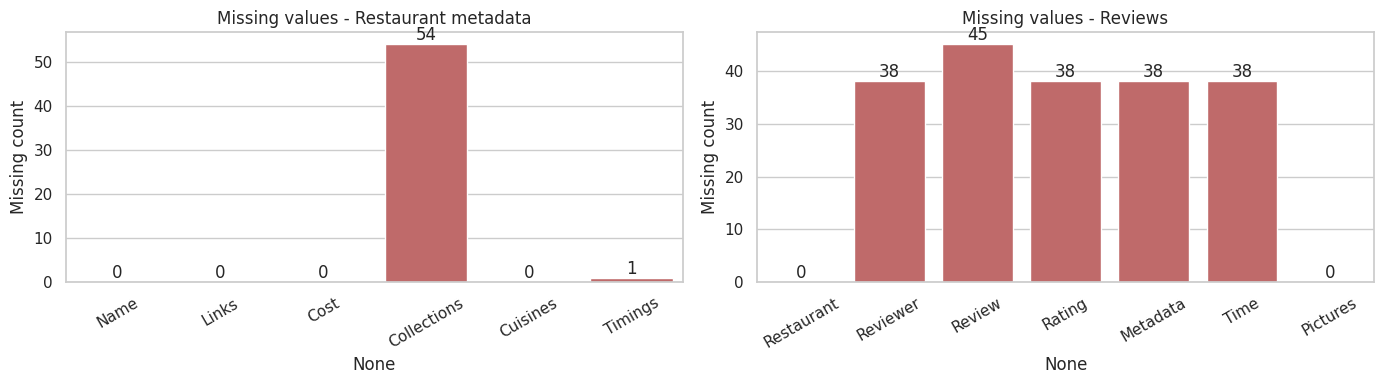

In [14]:
# Visualizing the missing values
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, df, title in zip(axes, [restaurants, reviews], ['Restaurant metadata', 'Reviews']):
    miss = df.isnull().sum()
    sns.barplot(x=miss.index, y=miss.values, ax=ax, color='indianred')
    ax.set_title(f'Missing values - {title}')
    ax.set_ylabel('Missing count')
    ax.tick_params(axis='x', rotation=30)
    for i, v in enumerate(miss.values):
        ax.text(i, v, str(v), ha='center', va='bottom')
plt.tight_layout()
plt.show()

### What did you know about your dataset?

* **Restaurant metadata:** 105 restaurants x 6 columns (Name, Links, Cost, Collections, Cuisines, Timings). All names are unique, there are no duplicate rows, and the Zomato links show the restaurants are in Hyderabad. `Cost` is stored as text with thousands separators; `Collections` is empty for 54 restaurants (they simply have no Zomato tag) and `Timings` is missing for 1.
* **Review data:** 10,000 reviews x 7 columns for 100 restaurants (exactly 100 reviews per restaurant, so five metadata restaurants have no reviews). There are 36 duplicate rows and 38 rows with no rating / reviewer / metadata / time, and 45 reviews have no text. `Rating` is stored as text because one row contains the word "Like".
* `Metadata` ("12 Reviews , 206 Followers") has to be parsed into numbers, and `Time` converted to a date-time. Both files are joined through the restaurant name.

## ***2. Understanding Your Variables***

In [15]:
# Dataset Columns
print("Restaurant columns:", list(restaurants.columns))
print("Review columns    :", list(reviews.columns))

Restaurant columns: ['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']
Review columns    : ['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']


In [16]:
# Dataset Describe
print("=== Restaurant metadata ===")
display(restaurants.describe(include='all').T)
print("\n=== Reviews ===")
display(reviews.describe(include='all').T)

=== Restaurant metadata ===


,count,unique,top,freq
Name,105,105,Beyond Flavours,1
Links,105,105,https://www.zomato.com/hyderabad/beyond-flavou...,1
Cost,105,29,500,13
Collections,51,42,Food Hygiene Rated Restaurants in Hyderabad,4
Cuisines,105,92,"North Indian, Chinese",4
Timings,104,77,11 AM to 11 PM,6



=== Reviews ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Restaurant,10000,100,Beyond Flavours,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reviewer,9962,7446,Parijat Ray,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review,9955,9364,good,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9962,10,5,3832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Metadata,9962,2477,1 Review,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9962,9782,7/29/2018 20:34,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pictures,10000.0,NaN,NaN,NaN,0.7486,2.570381,0.0,0.0,0.0,0.0,64.0


### Variables Description

**Restaurant data:** `Name` - restaurant name | `Links` - Zomato URL | `Cost` - estimated cost per person/for two (Rs) | `Collections` - Zomato category tags (e.g. "Great Buffets", "Hyderabad's Hottest") | `Cuisines` - cuisines served (comma separated) | `Timings` - opening hours.

**Review data:** `Restaurant` - restaurant reviewed | `Reviewer` - reviewer name | `Review` - review text | `Rating` - 1 to 5 (half-stars exist) | `Metadata` - reviewer's number of reviews and followers | `Time` - date and time of review | `Pictures` - number of pictures posted with the review.

### Check Unique Values for each variable.

In [17]:
# Check Unique Values for each variable.
for name, df in [('Restaurants', restaurants), ('Reviews', reviews)]:
    print(f"--- {name} ---")
    for col in df.columns:
        print(f"{col:<12}: {df[col].nunique()} unique values")
    print()

--- Restaurants ---
Name        : 105 unique values
Links       : 105 unique values
Cost        : 29 unique values
Collections : 42 unique values
Cuisines    : 92 unique values
Timings     : 77 unique values

--- Reviews ---
Restaurant  : 100 unique values
Reviewer    : 7446 unique values
Review      : 9364 unique values
Rating      : 10 unique values
Metadata    : 2477 unique values
Time        : 9782 unique values
Pictures    : 36 unique values



## 3. ***Data Wrangling***

### Data Wrangling Code

In [18]:
# Write your code to make your dataset analysis ready.
rest = restaurants.copy()
rev = reviews.copy()

# ---- Restaurant metadata ----
rest['Cost'] = rest['Cost'].astype(str).str.replace(',', '').astype(int)      # "1,300" -> 1300
rest['Collections'] = rest['Collections'].fillna('None')                      # no Zomato collection tag
rest['n_collections'] = rest['Collections'].apply(lambda s: 0 if s == 'None' else len(s.split(',')))
rest['cuisine_list'] = rest['Cuisines'].str.split(r',\s*')                    # list of cuisines
rest['n_cuisines'] = rest['cuisine_list'].str.len()

def parse_open_hours(text):
    """Daily opening hours from a Timings string (first day-group only, split shifts are summed)."""
    if pd.isna(text):
        return np.nan
    seg = str(text).split(')')[0]                                             # first "(Mon-Thu..)" group
    pat = (r'(\d{1,2})(?::(\d{2}))?\s*(am|pm|noon|midnight)?\s*to\s*'
           r'(\d{1,2})(?::(\d{2}))?\s*(am|pm|noon|midnight)')
    total = 0.0
    for h1, m1, p1, h2, m2, p2 in re.findall(pat, seg, flags=re.I):
        def to_hour(h, m, p):
            h, m, p = int(h), int(m or 0), p.lower()
            if p == 'noon': h = 12
            elif p == 'midnight': h = 0
            elif p == 'pm': h = h % 12 + 12
            elif p == 'am': h = h % 12
            return h + m / 60
        start, end = to_hour(h1, m1, p1 or p2), to_hour(h2, m2, p2)
        total += (end - start) % 24 or 24                                     # overnight closing -> +24h
    return min(total, 24) if total > 0 else np.nan

rest['open_hours'] = rest['Timings'].apply(parse_open_hours)

# ---- Reviews ----
rev = rev.drop_duplicates().copy()                                            # remove exact duplicate reviews
rev['Rating'] = pd.to_numeric(rev['Rating'], errors='coerce')                 # stray "Like" -> NaN
rev = rev.dropna(subset=['Rating']).copy()                                    # rows with no rating are unusable
rev['Review'] = rev['Review'].fillna('').astype(str)                          # rating-only reviews -> empty text
rev['Time'] = pd.to_datetime(rev['Time'], errors='coerce')
rev['reviewer_reviews'] = rev['Metadata'].str.extract(r'(\d+)\s+(?:Review|Post)', expand=False).astype(float)
rev['reviewer_followers'] = rev['Metadata'].str.extract(r'(\d+)\s+Follower', expand=False).astype(float).fillna(0)
rev['review_len'] = rev['Review'].str.split().str.len()
rev['year'] = rev['Time'].dt.year
rev['month'] = rev['Time'].dt.to_period('M').dt.to_timestamp()
rev['hour'] = rev['Time'].dt.hour
rev['weekday'] = rev['Time'].dt.day_name()
rev['has_picture'] = (rev['Pictures'] > 0).astype(int)
rev['sentiment_label'] = pd.cut(rev['Rating'], bins=[0, 2.5, 3.5, 5],
                                labels=['negative', 'neutral', 'positive'])   # rating -> sentiment class

# ---- Restaurant-level aggregation of review behaviour ----
agg = rev.groupby('Restaurant').agg(
    avg_rating=('Rating', 'mean'), n_reviews=('Rating', 'size'), rating_std=('Rating', 'std'),
    avg_pictures=('Pictures', 'mean'), pct_with_pictures=('has_picture', 'mean'),
    avg_followers=('reviewer_followers', 'mean'), avg_reviewer_reviews=('reviewer_reviews', 'mean'),
    avg_review_len=('review_len', 'mean')).reset_index().rename(columns={'Restaurant': 'Name'})
rest_stats = rest.merge(agg, on='Name', how='inner')                          # only restaurants that have reviews

print("Cleaned reviews :", rev.shape, "| Restaurants with reviews:", rest_stats.shape[0], "of", rest.shape[0])
print("Restaurants without reviews:", sorted(set(rest.Name) - set(rest_stats.Name)))
display(rest_stats.head())

Cleaned reviews : (9961, 16) | Restaurants with reviews: 100 of 105
Restaurants without reviews: ['Angaara Counts 3', 'IndiBlaze', 'Republic Of Noodles - Lemon Tree Hotel', 'Sweet Basket', 'Wich Please']


,Name,Links,Cost,Collections,Cuisines,Timings,n_collections,cuisine_list,n_cuisines,open_hours,avg_rating,n_reviews,rating_std,avg_pictures,pct_with_pictures,avg_followers,avg_reviewer_reviews,avg_review_len
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)",6,"[Chinese, Continental, Kebab, European, South ...",6,8.5,4.28,100,1.239746,0.39,0.11,100.61,7.52,47.92
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM,1,"[Biryani, North Indian, Chinese]",3,12.0,4.70,100,0.771984,0.02,0.02,7.98,2.52,29.90
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM",2,"[Asian, Mediterranean, North Indian, Desserts]",4,9.5,4.66,100,0.878704,0.55,0.14,27.48,6.67,47.68
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM,1,"[Biryani, North Indian, Chinese, Seafood, Beve...",5,14.0,3.21,100,1.603626,0.30,0.16,118.43,14.33,45.50
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,1200,"Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no...",5,"[Asian, Continental, North Indian, Chinese, Me...",5,11.0,4.34,100,1.065719,0.44,0.17,70.10,18.31,48.80


### What all manipulations have you done and insights you found?

* **Cost** converted from text to integer; **Collections** NaN filled with "None" and counted (`n_collections`); **Cuisines** split into a list (`n_cuisines`); **Timings** parsed into daily opening hours (`open_hours`, first day-group, split shifts summed).
* **Reviews:** removed 36 duplicates and the 38 unrated rows (this also removes the stray "Like" rating); empty review text kept as an empty string; **Time** converted to datetime (year, month, hour, weekday); **Metadata** split into `reviewer_reviews` and `reviewer_followers`; added `review_len`, `has_picture` and a 3-class `sentiment_label` (negative <= 2.5, neutral 3-3.5, positive >= 4).
* Review behaviour was **aggregated per restaurant** (average rating, rating spread, pictures, reviewer followers, review length) and merged with the metadata. 100 of the 105 restaurants have reviews.
* **Insights:** after cleaning, 9,961 reviews remain; the mean rating is 3.60, 63% of reviews are 4-5 stars; every restaurant has at most 100 reviews, which means the data is a *sample* of the most recent reviews per restaurant (important when reading the time-trend chart).

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

### Univariate analysis

#### Chart - 1 - Rating distribution (countplot)

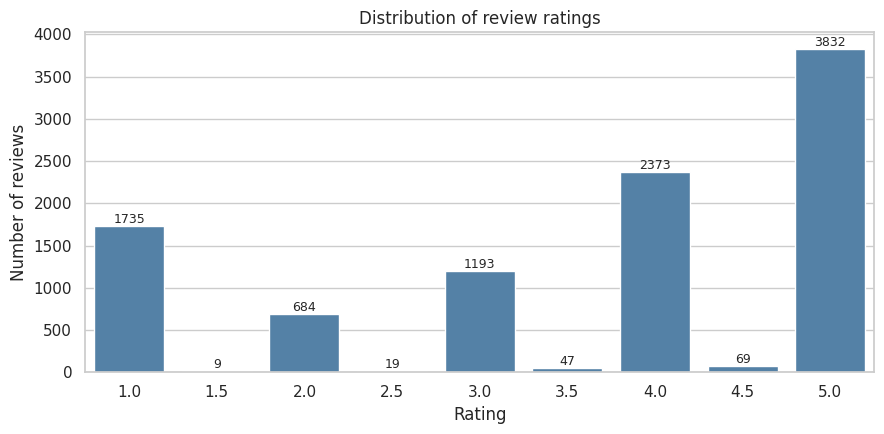

count    9961.00
mean        3.60
std         1.48
min         1.00
25%         3.00
50%         4.00
75%         5.00
max         5.00
Name: Rating, dtype: float64
Share of 4-5 star reviews: 63.0% | Share of 1-2 star reviews: 24.4%


In [19]:
# Chart - 1 visualization code
order = sorted(rev['Rating'].unique())
plt.figure(figsize=(9, 4.5))
ax = sns.countplot(data=rev, x='Rating', order=order, color='steelblue')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.title('Distribution of review ratings')
plt.xlabel('Rating'); plt.ylabel('Number of reviews')
plt.tight_layout(); plt.show()
print(rev['Rating'].describe().round(2))
print(f"Share of 4-5 star reviews: {(rev['Rating'] >= 4).mean():.1%} | Share of 1-2 star reviews: {(rev['Rating'] <= 2).mean():.1%}")

##### 1. Why did you pick the specific chart?
A count plot is the simplest way to see how a discrete, ordered variable such as a 1-5 star rating is distributed, including whether the distribution is skewed or has multiple peaks.

##### 2. What is/are the insight(s) found from the chart?
Ratings are strongly polarised: 5 stars is the single most common rating (about 3,800 reviews) and 63% of reviews are 4-5 stars, but 1 star is the second most frequent value (about 1,700 reviews) and 24.4% of reviews are 1-2 stars. Only a minority sit in the middle (3 stars). The mean is 3.60.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.
**Positive:** a majority of customers are satisfied, which supports Zomato's value as a trustworthy discovery platform. **Negative / risk:** the large 1-star group shows many customers have a bad experience; people choose to write reviews mainly when they are delighted or angry, so averages hide the 'average' experience. Restaurants in the 1-2 star group lose repeat customers, and Zomato should offer them quality-improvement support.

#### Chart - 2 - Cost for two - histogram with KDE and boxplot

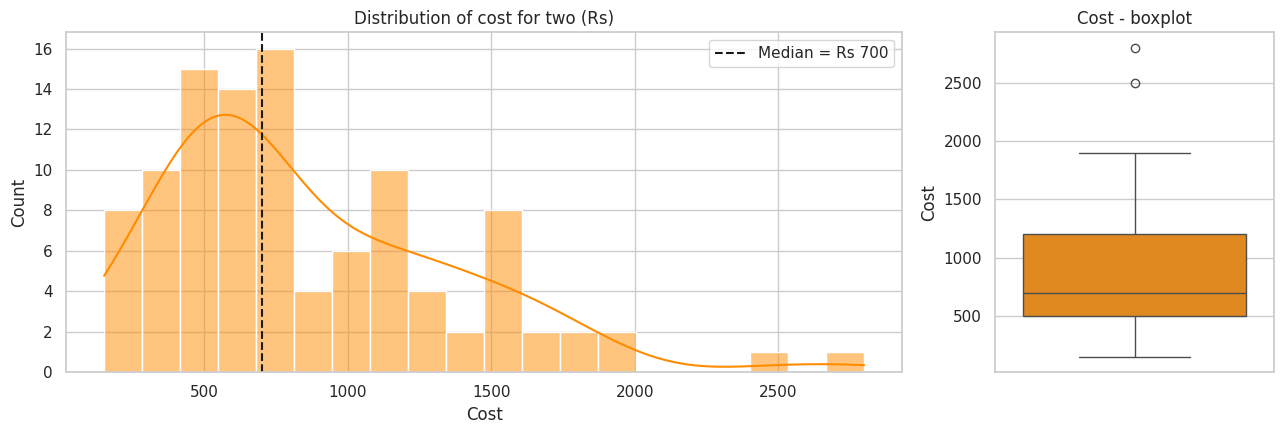

count     105.0
mean      861.0
std       510.0
min       150.0
25%       500.0
50%       700.0
75%      1200.0
max      2800.0
Name: Cost, dtype: float64
Skewness: 1.14


In [20]:
# Chart - 2 visualization code
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [3, 1]})
sns.histplot(rest['Cost'], bins=20, kde=True, color='darkorange', ax=axes[0])
axes[0].axvline(rest['Cost'].median(), color='k', ls='--', label=f"Median = Rs {rest['Cost'].median():.0f}")
axes[0].set_title('Distribution of cost for two (Rs)'); axes[0].legend()
sns.boxplot(y=rest['Cost'], color='darkorange', ax=axes[1])
axes[1].set_title('Cost - boxplot')
plt.tight_layout(); plt.show()
print(rest['Cost'].describe().round(0))
print("Skewness:", round(rest['Cost'].skew(), 2))

##### 1. Why did you pick the specific chart?
A histogram + KDE shows the shape of a continuous variable and the boxplot shows the median, spread and outliers in one glance.

##### 2. What is/are the insight(s) found from the chart?
Cost is right-skewed (skewness 1.14): the median restaurant costs Rs 700, the mean is Rs 861, the middle 50% costs Rs 500-1,200, the cheapest is Rs 150 and the most expensive Rs 2,800. Two restaurants are IQR outliers on the premium side. Rs 500 is the single most common price point.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.
**Positive:** the market is dominated by affordable restaurants, so promotions around Rs 500-800 reach the majority; a smaller premium tier (Rs 1,200+) offers high-margin partnerships. **Risk:** the premium segment is thin, so over-dependence on it would be risky, and budget restaurants have thin margins, so they are sensitive to commissions and delivery costs. The skew is the reason we log-transform cost before clustering.

#### Chart - 3 - Top 10 cuisines (bar chart)

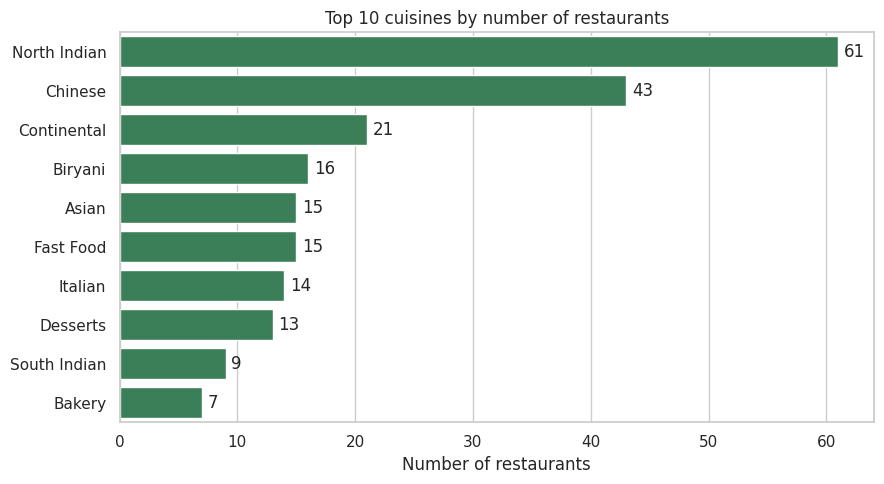

Distinct cuisines: 44


In [21]:
# Chart - 3 visualization code
cuisine_counts = rest.explode('cuisine_list')['cuisine_list'].value_counts()
top10 = cuisine_counts.head(10)
plt.figure(figsize=(9, 5))
sns.barplot(x=top10.values, y=top10.index, color='seagreen')
for i, v in enumerate(top10.values):
    plt.text(v + 0.5, i, str(v), va='center')
plt.title('Top 10 cuisines by number of restaurants')
plt.xlabel('Number of restaurants'); plt.ylabel('')
plt.tight_layout(); plt.show()
print("Distinct cuisines:", len(cuisine_counts))

##### 1. Why did you pick the specific chart?
A horizontal bar chart is the clearest way to compare category counts when the labels (cuisine names) are long.

##### 2. What is/are the insight(s) found from the chart?
There are 44 distinct cuisines, but the market is concentrated: North Indian is served by 61 of the 105 restaurants, Chinese by 43, Continental by 21, then Biryani (16), Asian (15), Fast Food (15), Italian (14) and Desserts (13). Many cuisines (e.g. Bakery, Seafood) appear only a handful of times.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.
**Positive:** Zomato can build strong North Indian / Chinese / Biryani collections where customers have the widest choice. **Negative:** the market is over-supplied in North Indian and Chinese (high competition and discount pressure for each restaurant), while under-served cuisines (e.g. Italian, Desserts, South Indian) are an opportunity to onboard new restaurants and differentiate.

#### Chart - 4 - Reviews and average rating over time (line charts)

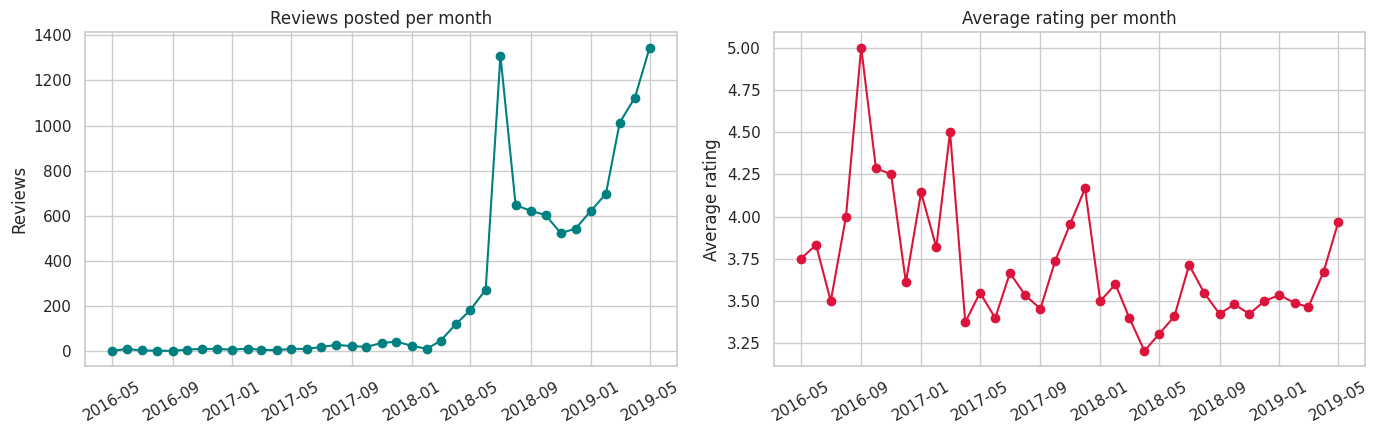

Date range: 2016-05-31 to 2019-05-25
            n_reviews  avg_rating
month                            
2019-05-01       1346        3.97
2018-07-01       1310        3.71
2019-04-01       1124        3.67


In [22]:
# Chart - 4 visualization code
monthly = rev.groupby('month').agg(n_reviews=('Rating', 'size'), avg_rating=('Rating', 'mean'))
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(monthly.index, monthly['n_reviews'], marker='o', color='teal')
axes[0].set_title('Reviews posted per month'); axes[0].set_ylabel('Reviews'); axes[0].tick_params(axis='x', rotation=30)
axes[1].plot(monthly.index, monthly['avg_rating'], marker='o', color='crimson')
axes[1].set_title('Average rating per month'); axes[1].set_ylabel('Average rating'); axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()
print("Date range:", rev['Time'].min().date(), "to", rev['Time'].max().date())
print(monthly.sort_values('n_reviews', ascending=False).head(3).round(2))

##### 1. Why did you pick the specific chart?
Line charts are the standard tool for trends over time; two panels let us see volume and quality together.

##### 2. What is/are the insight(s) found from the chart?
The data runs from May 2016 to May 2019, but about 97% of the reviews are from 2018-2019 (4,903 in 2018, 4,802 in 2019). Average rating by year is 3.97 (2016, only 43 reviews), 3.81 (2017), 3.52 (2018) and 3.67 (2019). May 2019 (1,346 reviews, mean 3.97) and July 2018 (1,310 reviews) are the busiest months. Because each restaurant contributes exactly its latest ~100 reviews, the volume trend is partly an artefact of sampling and not a true growth rate.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.
The dip in 2018 and partial recovery in 2019 suggests customer satisfaction is not rising automatically with volume; Zomato should track a rolling average rating per restaurant and alert owners when it drops. We should not use this chart for demand forecasting because of the sampling limitation, which we state openly.

### Bivariate analysis

#### Chart - 5 - Top 10 and bottom 10 restaurants by average rating

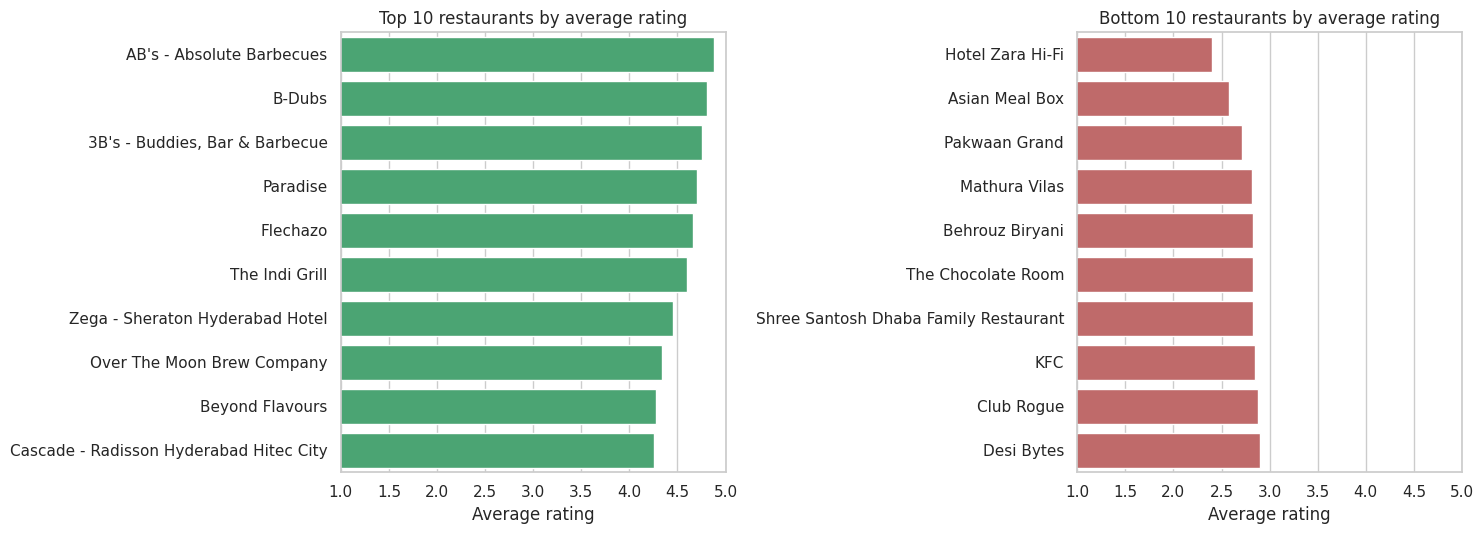

,Name,Cost,avg_rating,n_reviews
14,AB's - Absolute Barbecues,1500,4.88,100
22,B-Dubs,1600,4.81,100
27,"3B's - Buddies, Bar & Barbecue",1100,4.76,100
1,Paradise,800,4.70,100
2,Flechazo,1300,4.66,100


In [23]:
# Chart - 5 visualization code
ranked = rest_stats.sort_values('avg_rating', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.barplot(data=ranked.head(10), x='avg_rating', y='Name', color='mediumseagreen', ax=axes[0])
axes[0].set_title('Top 10 restaurants by average rating'); axes[0].set_xlim(1, 5)
sns.barplot(data=ranked.tail(10).iloc[::-1], x='avg_rating', y='Name', color='indianred', ax=axes[1])
axes[1].set_title('Bottom 10 restaurants by average rating'); axes[1].set_xlim(1, 5)
for ax in axes:
    ax.set_xlabel('Average rating'); ax.set_ylabel('')
plt.tight_layout(); plt.show()
display(ranked[['Name', 'Cost', 'avg_rating', 'n_reviews']].head(5).round(2))

##### 1. Why did you pick the specific chart?
Side-by-side ranked bars quickly show who the best and worst performers are, and how wide the gap is.

##### 2. What is/are the insight(s) found from the chart?
Average restaurant rating ranges from 2.40 to 4.88 (mean 3.60). The best are AB's - Absolute Barbecues (4.88), B-Dubs (4.81), 3B's - Buddies, Bar & Barbecue (4.76), Paradise (4.70) and Flechazo (4.66) - all barbecue / buffet / biryani destinations costing Rs 800-1,600. The weakest are Hotel Zara Hi-Fi (2.40), Asian Meal Box (2.58), Pakwaan Grand (2.71), Mathura Vilas (2.82) and Behrouz Biryani (2.82), mostly Rs 200-600 restaurants.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.
**Positive:** the best performers can be featured as benchmarks and in 'Top-Rated' collections. **Negative:** the bottom group shows that ratings below 3 are common among low-cost restaurants; these outlets risk delisting or low visibility, so Zomato can offer them quality audits and hygiene ratings before they churn.

#### Chart - 6 - Cost vs average rating (scatter + regression)

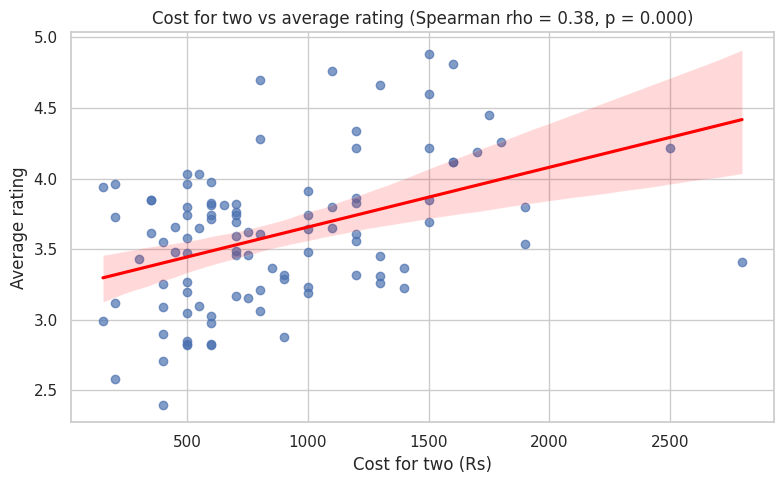

In [24]:
# Chart - 6 visualization code
rho, p = stats.spearmanr(rest_stats['Cost'], rest_stats['avg_rating'])
plt.figure(figsize=(8, 5))
sns.regplot(data=rest_stats, x='Cost', y='avg_rating', scatter_kws={'alpha': .7}, line_kws={'color': 'red'})
plt.title(f'Cost for two vs average rating (Spearman rho = {rho:.2f}, p = {p:.3f})')
plt.xlabel('Cost for two (Rs)'); plt.ylabel('Average rating')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
A scatter plot with a regression line is the standard way to test whether two numeric variables are related, and it directly answers the question 'Is cost correlated to rating?' from the project flow.

##### 2. What is/are the insight(s) found from the chart?
There is a moderate positive relationship: Spearman rho = 0.38 (p < 0.001). More expensive restaurants tend to have higher average ratings, but the scatter is wide, so price does not guarantee quality - there are cheap restaurants with high ratings and expensive ones with low ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.
**Positive:** customers see value in paying more, so premium positioning works and 'good value' budget restaurants stand out strongly. **Negative:** cheap restaurants face a structural rating disadvantage (expectations are met less often), which may reduce their visibility in rating-sorted lists; Zomato could introduce price-band-aware ranking to be fair to them.

#### Chart - 7 - Cost distribution across cuisines (boxplot)

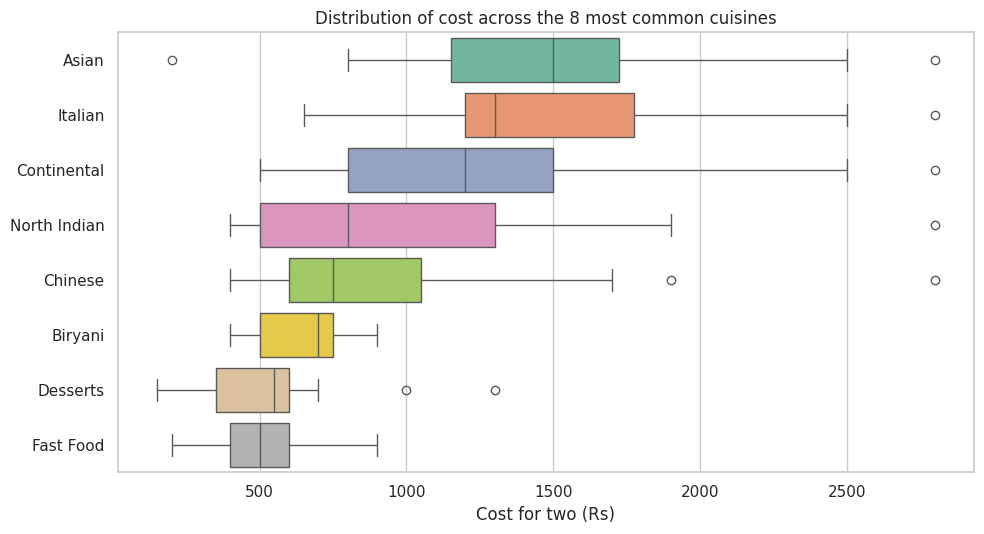

              count  median    mean
cuisine_list                       
Asian            15  1500.0  1460.0
Italian          14  1300.0  1532.0
Continental      21  1200.0  1307.0
North Indian     61   800.0   956.0
Chinese          43   750.0   895.0
Biryani          16   700.0   650.0
Desserts         13   550.0   569.0
Fast Food        15   500.0   493.0


In [25]:
# Chart - 7 visualization code
top8 = cuisine_counts.head(8).index
cx = rest.explode('cuisine_list')
cx = cx[cx['cuisine_list'].isin(top8)]
order = cx.groupby('cuisine_list')['Cost'].median().sort_values(ascending=False).index
plt.figure(figsize=(10, 5.5))
sns.boxplot(data=cx, y='cuisine_list', x='Cost', order=order, palette='Set2')
plt.title('Distribution of cost across the 8 most common cuisines')
plt.xlabel('Cost for two (Rs)'); plt.ylabel('')
plt.tight_layout(); plt.show()
print(cx.groupby('cuisine_list')['Cost'].agg(['count', 'median', 'mean']).round(0).loc[order])

##### 1. Why did you pick the specific chart?
A box plot compares the distribution of a numeric variable (cost) across several categories (cuisines) and exposes the median and the spread together - exactly the 'distribution of cost across different cuisines' idea of the project flow.

##### 2. What is/are the insight(s) found from the chart?
Median cost for two: Asian Rs 1,500, Italian Rs 1,300, Continental Rs 1,200, North Indian Rs 800, Chinese Rs 750, Biryani Rs 700, Desserts Rs 550 and Fast Food Rs 500. Asian, Italian and Continental restaurants are premium; Biryani, Fast Food and Desserts are budget cuisines. North Indian and Chinese have wide spreads because they are served at every price point.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.
Cuisine is a useful proxy for price tier, so cuisine-based targeting (for example, premium Asian/Continental dining campaigns vs fast food delivery offers) can raise conversion. The risk is that budget cuisines have low average ticket sizes, so revenue growth must come from volume.

#### Chart - 8 - Best-rated restaurants within each popular cuisine

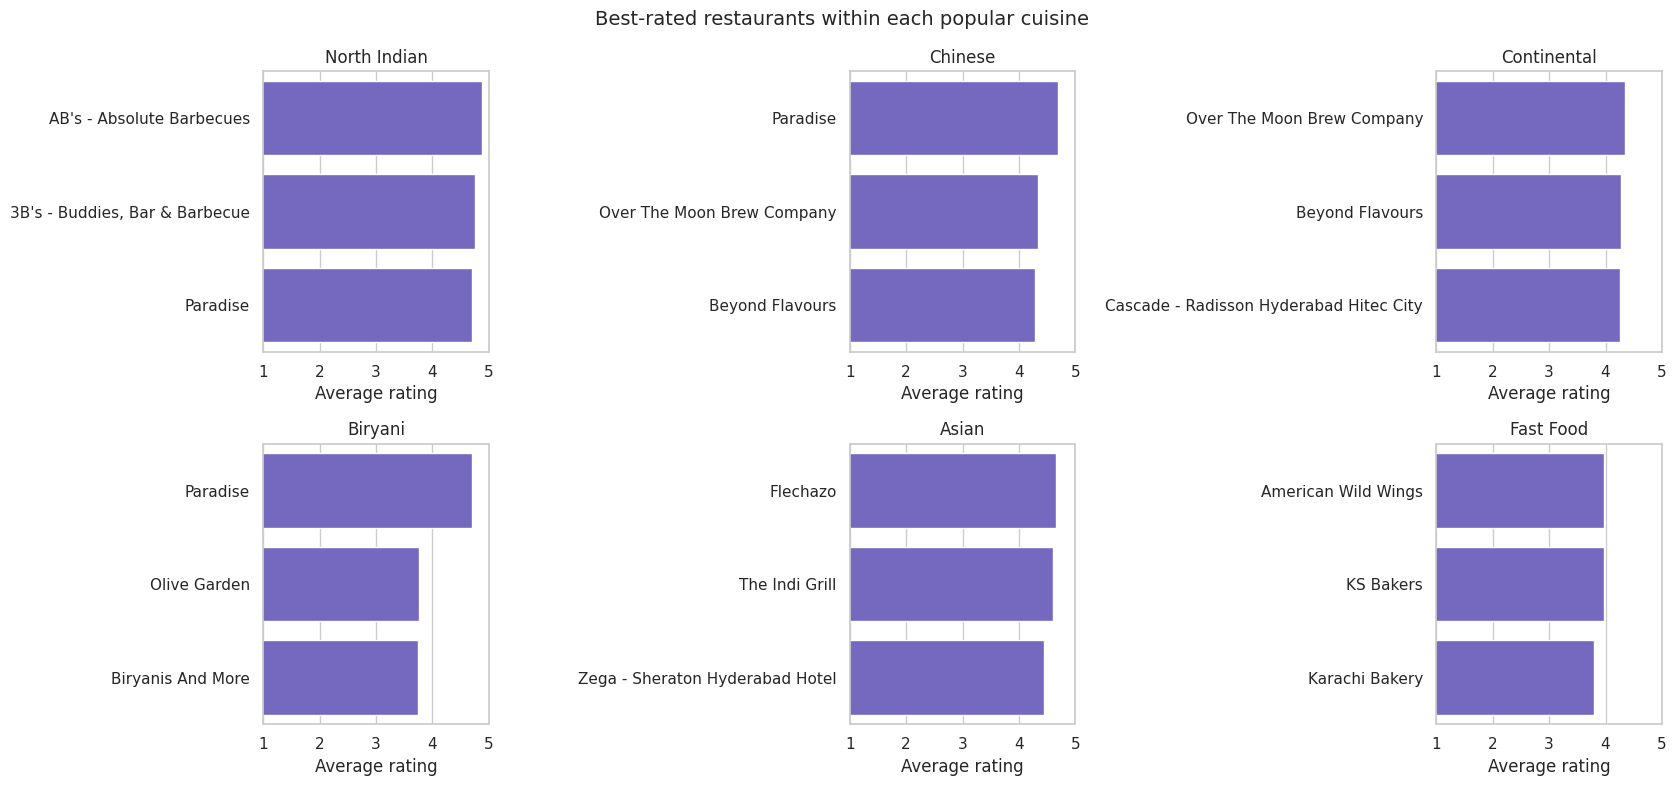

In [26]:
# Chart - 8 visualization code
top6 = list(cuisine_counts.head(6).index)
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, cuisine in zip(axes.ravel(), top6):
    sub = rest_stats[rest_stats['cuisine_list'].apply(lambda l: cuisine in l)].nlargest(3, 'avg_rating')
    sns.barplot(data=sub, x='avg_rating', y='Name', color='slateblue', ax=ax)
    ax.set_title(cuisine); ax.set_xlim(1, 5); ax.set_xlabel('Average rating'); ax.set_ylabel('')
plt.suptitle('Best-rated restaurants within each popular cuisine', fontsize=14)
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
Small multiples (one panel per cuisine) allow a fair comparison inside each cuisine, covering the 'most popular restaurants grouped by cuisines' idea of the project flow.

##### 2. What is/are the insight(s) found from the chart?
North Indian is led by AB's Absolute Barbecues (4.88), Biryani by Paradise (4.70) - far ahead of the next biryani restaurant (3.76), Asian by Flechazo (4.66) and The Indi Grill (4.60), Continental by Over The Moon Brew Company (4.34), Chinese by Paradise (4.70). In Fast Food even the best restaurant (American Wild Wings) reaches only 3.97.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.
**Positive:** clear cuisine champions can anchor 'best of' collections and be used for cross-promotion. **Negative:** the Biryani and Fast Food cuisines have a very low rating ceiling beyond one champion, indicating inconsistent quality in these high-volume cuisines - an opportunity for standardisation programmes, and a risk of customers losing trust in them.

#### Chart - 9 - Rating by number of pictures posted with the review

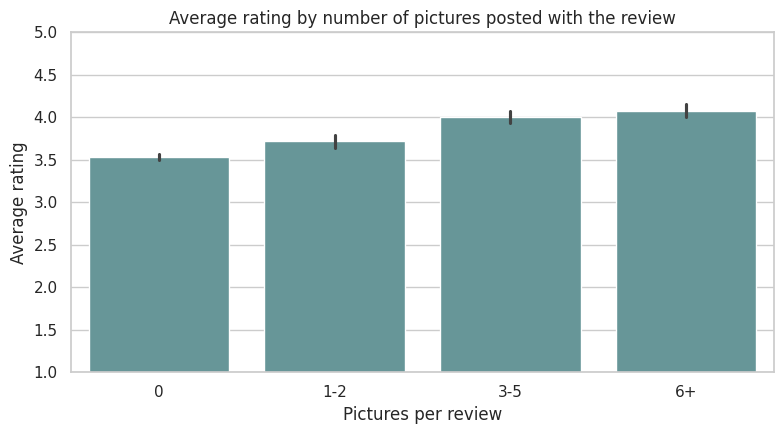

          count  mean
Pictures             
0          7978  3.54
1-2        1089  3.72
3-5         491  4.00
6+          403  4.08


In [27]:
# Chart - 9 visualization code
pic_bucket = pd.cut(rev['Pictures'], bins=[-1, 0, 2, 5, 1000], labels=['0', '1-2', '3-5', '6+'])
plt.figure(figsize=(8, 4.5))
sns.barplot(x=pic_bucket, y=rev['Rating'], color='cadetblue', errorbar=('ci', 95))
plt.title('Average rating by number of pictures posted with the review')
plt.xlabel('Pictures per review'); plt.ylabel('Average rating'); plt.ylim(1, 5)
plt.tight_layout(); plt.show()
print(rev.groupby(pic_bucket)['Rating'].agg(['count', 'mean']).round(2))

##### 1. Why did you pick the specific chart?
A bar chart with 95% confidence intervals compares the average rating across ordered groups of picture counts and shows whether differences are statistically meaningful.

##### 2. What is/are the insight(s) found from the chart?
Reviews with no pictures average 3.54 stars (7,978 reviews), 1-2 pictures 3.72, 3-5 pictures 4.00 and 6+ pictures 4.08. Rating rises steadily with the number of pictures - customers who take the trouble to photograph their meal are mostly happy ones.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.
**Positive:** encouraging photo uploads (rewards, badges) enriches restaurant pages and correlates with happier content, increasing conversions. **Caution:** photo-rich reviews skew positive, so these ratings alone overstate quality; Zomato should weight text reviews and photos together when ranking.

#### Chart - 10 - Review length by rating (boxplot)

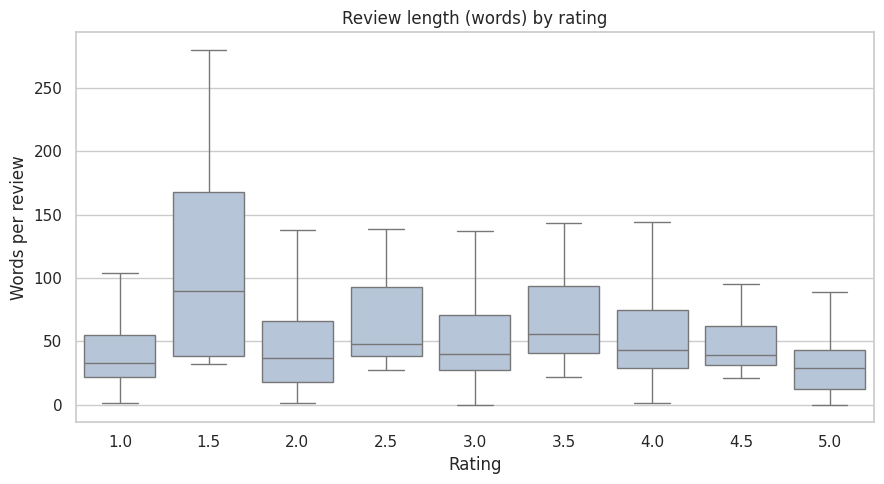

sentiment_label
negative    34.0
neutral     41.0
positive    33.0
Name: review_len, dtype: float64


In [28]:
# Chart - 10 visualization code
plt.figure(figsize=(9, 5))
sns.boxplot(data=rev, x='Rating', y='review_len', showfliers=False, color='lightsteelblue')
plt.title('Review length (words) by rating')
plt.xlabel('Rating'); plt.ylabel('Words per review')
plt.tight_layout(); plt.show()
print(rev.groupby('sentiment_label')['review_len'].median())

##### 1. Why did you pick the specific chart?
A box plot of review length per rating shows how much customers write at each satisfaction level, without being distorted by a few extremely long reviews (outliers hidden).

##### 2. What is/are the insight(s) found from the chart?
Median review length is 34 words for negative, 41 for neutral and 33 for positive reviews. Neutral / mixed reviews are the longest (people explain pros and cons), while happy customers write the shortest comments ('Good food, nice service').

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.
Long mixed reviews contain the most actionable feedback for owners, so text analytics should prioritise 3-star reviews. Short, positive reviews carry little information; Zomato could prompt for specifics (dish, service, ambience) to improve review quality.

#### Chart - 11 - Rating and volume by reviewer follower count (critics)

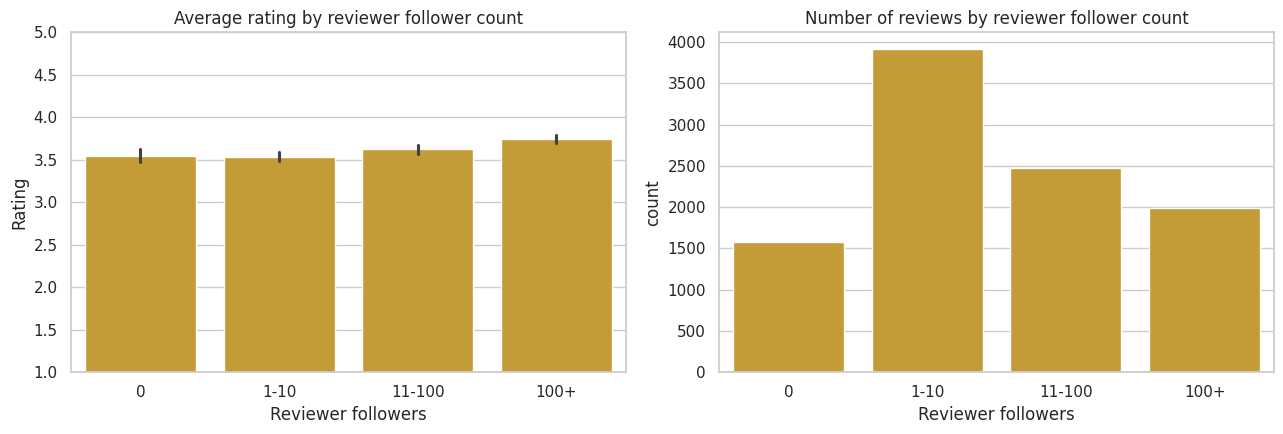

                    count  mean
reviewer_followers             
0                    1578  3.55
1-10                 3922  3.53
11-100               2469  3.63
100+                 1992  3.74


In [29]:
# Chart - 11 visualization code
tier = pd.cut(rev['reviewer_followers'], bins=[-1, 0, 10, 100, 1e7], labels=['0', '1-10', '11-100', '100+'])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=tier, y=rev['Rating'], color='goldenrod', ax=axes[0], errorbar=('ci', 95))
axes[0].set_title('Average rating by reviewer follower count'); axes[0].set_xlabel('Reviewer followers'); axes[0].set_ylim(1, 5)
sns.countplot(x=tier, color='goldenrod', ax=axes[1])
axes[1].set_title('Number of reviews by reviewer follower count'); axes[1].set_xlabel('Reviewer followers')
plt.tight_layout(); plt.show()
print(rev.groupby(tier)['Rating'].agg(['count', 'mean']).round(2))

##### 1. Why did you pick the specific chart?
Grouping reviewers by their number of followers lets us identify the influential 'critics' mentioned in the business context and compare their ratings to ordinary users.

##### 2. What is/are the insight(s) found from the chart?
Reviewer influence is very uneven: the median reviewer has only 7 followers (maximum 13,410). Average rating is 3.55 for reviewers with 0 followers, 3.53 for 1-10, 3.63 for 11-100 and 3.74 for 100+ followers. So influential reviewers are not harsher - if anything they are slightly more generous - and about 20% of all reviews (1,992) come from reviewers with 100+ followers.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.
**Positive:** the 100+ follower group is a ready-made set of micro-influencers for Zomato partnerships and restaurant-owner outreach. **Risk:** a bad experience for a 100+ follower reviewer travels much farther, so owners should prioritise service recovery for them.

### Multivariate analysis

#### Chart - 12 - Most frequent words in positive vs negative reviews

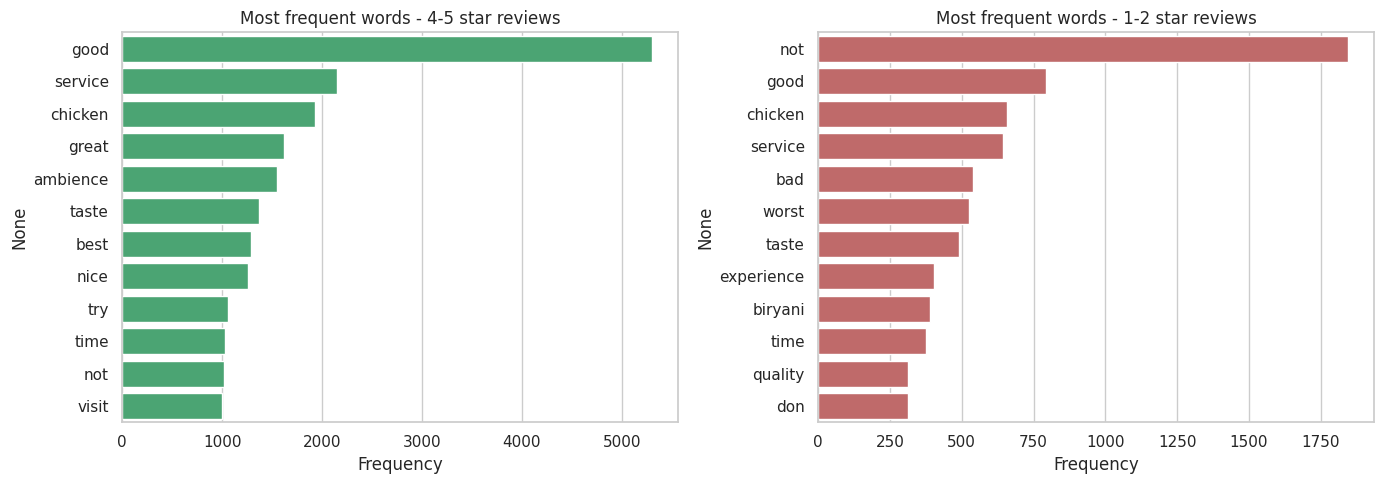

In [30]:
# Chart - 12 visualization code
quick_stop = set(ENGLISH_STOP_WORDS) - {'not', 'no', 'nor'}
quick_stop |= {'food', 'place', 'restaurant', 'ordered', 'order', 'really', 'also', 'just', 'one', 'got', 'like', 'went', 'us'}
def top_words(texts, n=12):
    words = [w for t in texts for w in re.findall(r"[a-z]{3,}", t.lower()) if w not in quick_stop]
    return pd.Series(Counter(words)).sort_values(ascending=False).head(n)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
pos_words = top_words(rev.loc[rev['Rating'] >= 4, 'Review'])
neg_words = top_words(rev.loc[rev['Rating'] <= 2, 'Review'])
sns.barplot(x=pos_words.values, y=pos_words.index, color='mediumseagreen', ax=axes[0]); axes[0].set_title('Most frequent words - 4-5 star reviews')
sns.barplot(x=neg_words.values, y=neg_words.index, color='indianred', ax=axes[1]); axes[1].set_title('Most frequent words - 1-2 star reviews')
for ax in axes: ax.set_xlabel('Frequency')
plt.tight_layout(); plt.show()

##### 1. Why did you pick the specific chart?
Comparing the top words of 4-5 star and 1-2 star reviews side by side turns thousands of text reviews into clear themes, a simple and explainable form of sentiment analysis.

##### 2. What is/are the insight(s) found from the chart?
Happy reviews talk about *good*, *service*, *chicken*, *great*, *ambience*, *taste*, *best* and *nice*. Unhappy reviews are dominated by *not* (1,843 occurrences - negations such as 'not good', 'not fresh'), *bad*, *worst*, *taste*, *experience*, *quality* and *service*. *Service*, *taste* and *chicken* appear in both lists: they are what customers care about most, and they decide whether the review is positive or negative. *Biryani* appears among the negative words, reflecting expectations for this dish.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.
**Positive:** owners know exactly which levers matter - taste, service, ambience. **Negative:** service and taste inconsistencies create negative growth through the 24% of 1-2 star reviews. Negations ('not') show why stop-word removal must keep 'not' in the sentiment model.

#### Chart - 13 - When do customers post reviews? (weekday x hour heatmap)

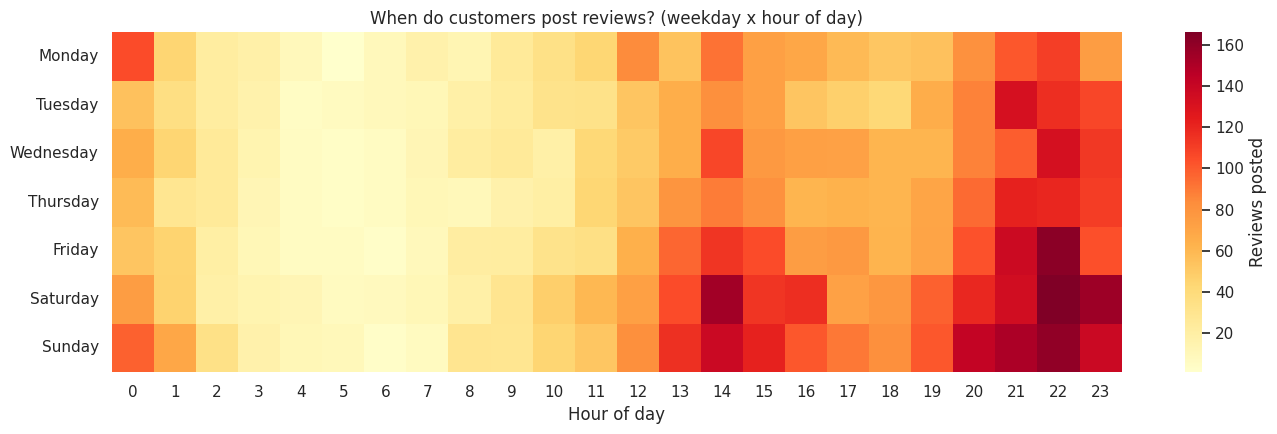

Busiest hour: 22 | Busiest weekday: Sunday


In [31]:
# Chart - 13 visualization code
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heat = rev.pivot_table(index='weekday', columns='hour', values='Rating', aggfunc='size', fill_value=0).reindex(days)
plt.figure(figsize=(14, 4.5))
sns.heatmap(heat, cmap='YlOrRd', cbar_kws={'label': 'Reviews posted'})
plt.title('When do customers post reviews? (weekday x hour of day)')
plt.xlabel('Hour of day'); plt.ylabel('')
plt.tight_layout(); plt.show()
print("Busiest hour:", int(rev['hour'].value_counts().idxmax()), "| Busiest weekday:", rev['weekday'].value_counts().idxmax())

##### 1. Why did you pick the specific chart?
A heatmap of two categorical dimensions (weekday and hour) with colour for volume reveals timing patterns that a bar chart cannot.

##### 2. What is/are the insight(s) found from the chart?
Review activity peaks in the evening: 10 pm is the busiest hour (968 reviews), followed by 9 pm (877), 11 pm (804) and a smaller lunchtime peak at 2 pm (776). Sunday (1,827) and Saturday (1,736) have the most reviews; Tuesday is the quietest (1,192).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.
Restaurants and Zomato can time engagement (review reminders, push notifications, dinner offers) for weekend evenings, and run weekday-lunch offers to fill the quiet Tuesday-Thursday slots. The risk is capacity: peak-hour crowding may cause service problems and negative reviews exactly when most customers are watching.

#### Chart - 14 - Correlation Heatmap

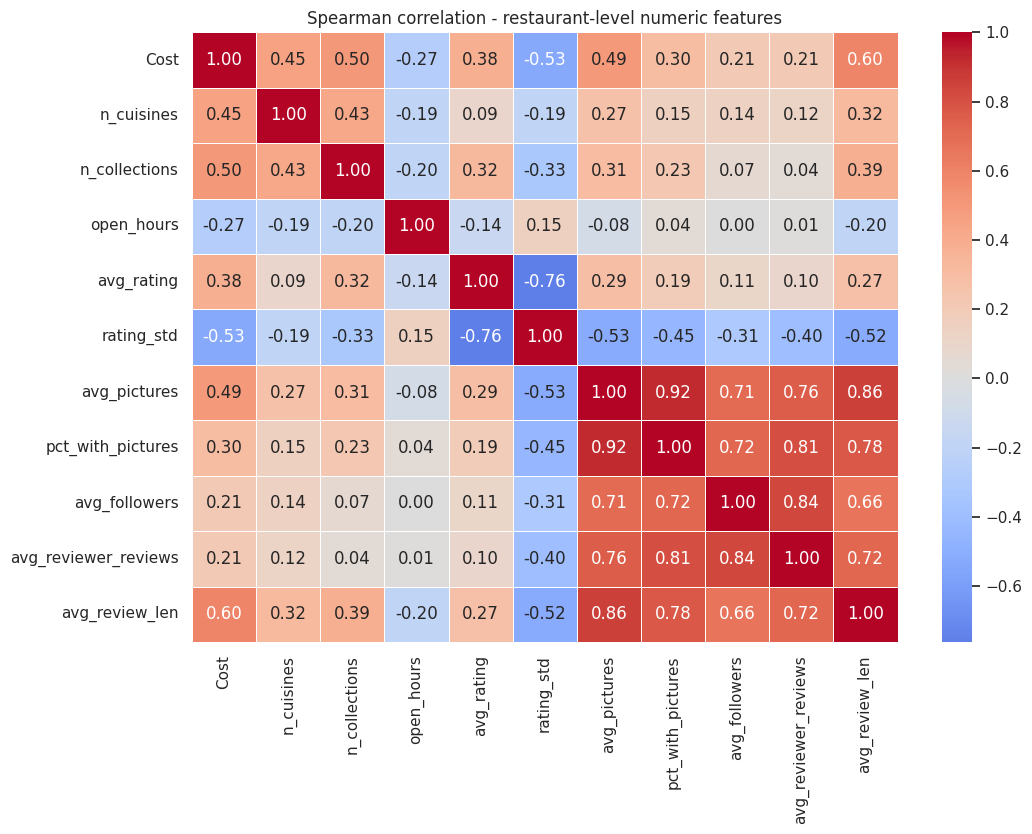

Strongest negative:
 avg_rating  rating_std     -0.76
Cost        rating_std     -0.53
rating_std  avg_pictures   -0.53
dtype: float64 

Strongest positive:
 pct_with_pictures  avg_reviewer_reviews    0.81
avg_followers      avg_reviewer_reviews    0.84
avg_pictures       avg_review_len          0.86
                   pct_with_pictures       0.92
dtype: float64


In [32]:
# Correlation Heatmap visualization code
num_cols = ['Cost', 'n_cuisines', 'n_collections', 'open_hours', 'avg_rating', 'rating_std',
            'avg_pictures', 'pct_with_pictures', 'avg_followers', 'avg_reviewer_reviews', 'avg_review_len']
corr = rest_stats[num_cols].corr(method='spearman')
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5)
plt.title('Spearman correlation - restaurant-level numeric features')
plt.tight_layout(); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().dropna().sort_values()
print("Strongest negative:\n", pairs.head(3).round(2), "\n\nStrongest positive:\n", pairs.tail(4).round(2))

##### 1. Why did you pick the specific chart?
A correlation heatmap shows all pairwise relationships between numeric restaurant features at once, helps spot redundant (collinear) features before clustering, and uses Spearman correlation because several variables are skewed.

##### 2. What is/are the insight(s) found from the chart?
* **Rating vs. rating spread:** strongly negative (-0.76): well-rated restaurants are also *consistently* rated; poorly-rated ones have polarised opinions.
* **Cost** is positively related to review length (0.60), pictures (0.49), number of collections (0.50), number of cuisines (0.45) and rating (0.38), and negatively to rating spread (-0.53): premium restaurants attract more engaged and consistent feedback.
* **Engagement features move together:** pictures per review vs. share of reviews with pictures (0.92), review length (0.86), reviewer followers vs. reviewer review count (0.84). They measure the same thing (an engaged, 'foodie' audience), so only one of them (pictures) is kept for clustering.
* `open_hours` is only weakly related to the other features (|r| <= 0.27; slightly negative with cost) - opening hours do not drive perceived quality.

#### Chart - 15 - Pair Plot

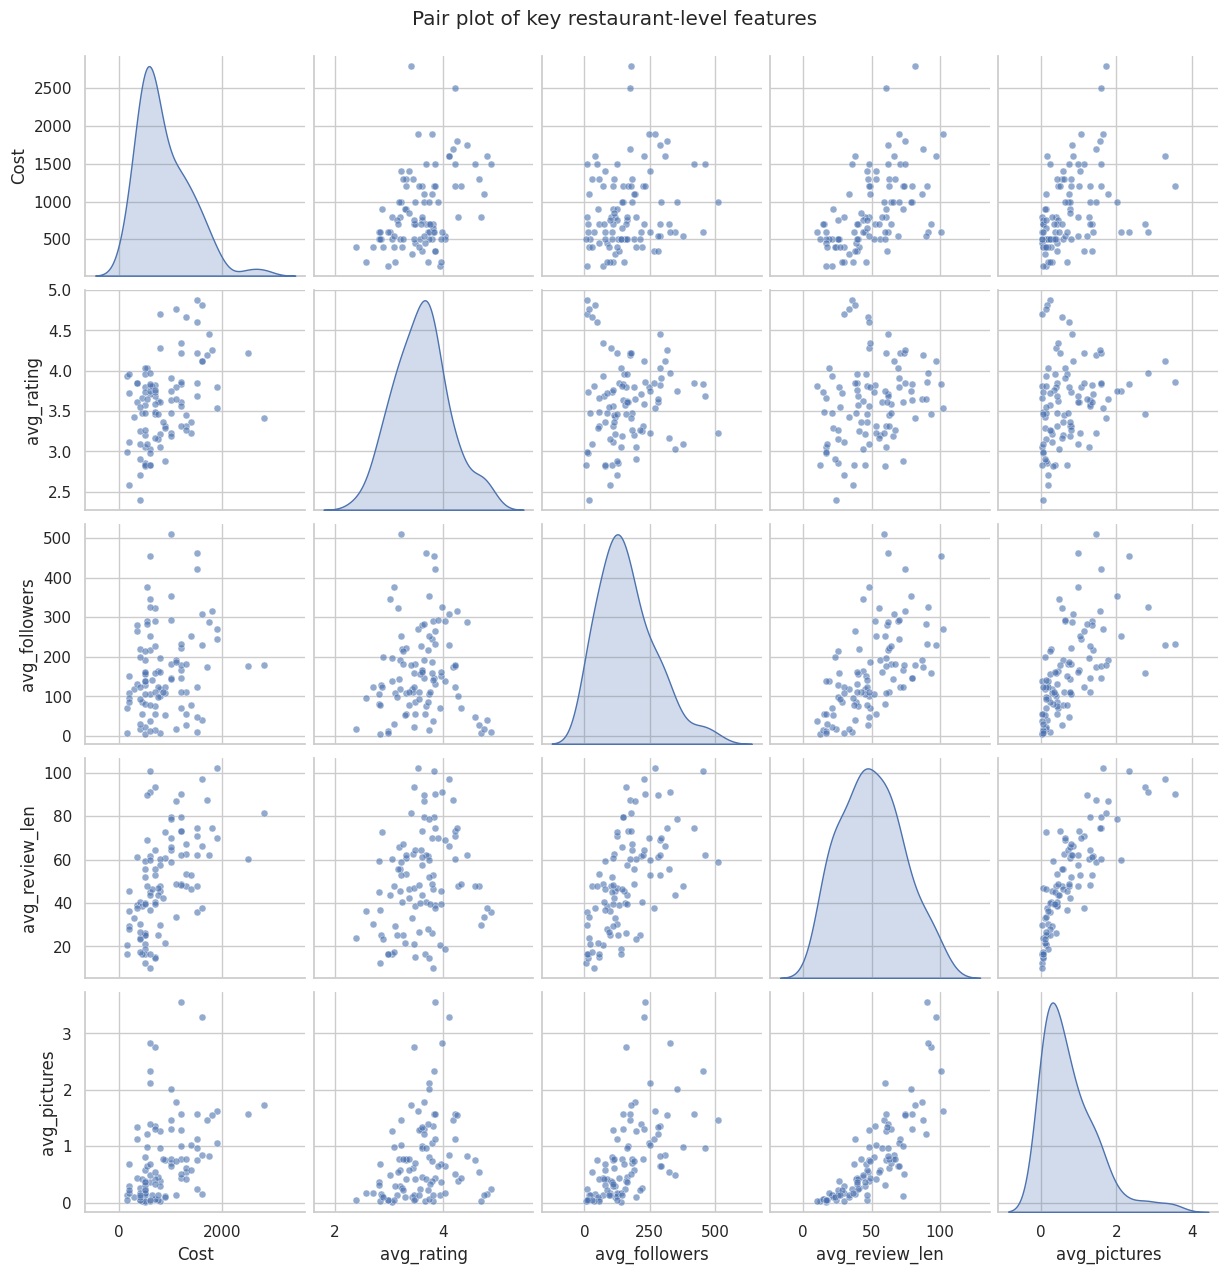

In [33]:
# Pair Plot visualization code
pp_cols = ['Cost', 'avg_rating', 'avg_followers', 'avg_review_len', 'avg_pictures']
sns.pairplot(rest_stats[pp_cols], diag_kind='kde', plot_kws={'alpha': .6, 's': 25})
plt.suptitle('Pair plot of key restaurant-level features', y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?
A pair plot is the best multivariate overview for a small dataset (100 restaurants): it shows every pairwise scatter plus each variable's distribution in a single figure, and it hints at clusters visually before we build any model.

##### 2. What is/are the insight(s) found from the chart?
Cost is right-skewed with most restaurants between Rs 400 and Rs 1,000 and a thin tail up to Rs 2,800; average rating is roughly bell-shaped around 3.6 with a small tail of restaurants above 4.5. Cost and rating show a loose upward relationship, and review length, pictures per review and reviewer followers rise together (an engaged-reviewer audience). Interestingly, the very top-rated restaurants (4.5+) attract reviewers with few followers, while the restaurants with the most influential reviewers are mid-rated. There are no clearly isolated blobs: the points form a continuum, which anticipates the moderate silhouette values of the clustering and tells us the segments will be overlapping *tiers* rather than separate islands.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

1. More expensive restaurants have higher average ratings (from Chart 6).
2. Reviews that include pictures have different (higher) ratings than reviews without pictures (from Chart 9).
3. Average rating differs across budget, mid-range and premium cost tiers (from Charts 6-7).

### Hypothetical Statement - 1
#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.
* **H0:** There is no monotonic correlation between a restaurant's cost for two and its average rating (rho = 0).
* **H1:** There is a correlation between cost and average rating (rho != 0).

#### 2. Perform an appropriate statistical test.

In [34]:
# Hypothesis 1 - Perform Statistical Test to obtain P-Value
rho, p_value = stats.spearmanr(rest_stats['Cost'], rest_stats['avg_rating'])
print(f"Spearman rho = {rho:.3f}, p-value = {p_value:.4f}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0", "at alpha = 0.05")

Spearman rho = 0.383, p-value = 0.0001
Reject H0 at alpha = 0.05


##### Which statistical test have you done to obtain P-Value?
Spearman rank correlation test. Result: rho = 0.383, **p = 0.0001 < 0.05 -> reject H0**: cost and rating are positively correlated (moderate strength).

##### Why did you choose the specific statistical test?
Cost is right-skewed and average rating is not perfectly normal, so a rank-based (non-parametric) correlation is safer than Pearson; it measures monotonic association and is robust to outliers.

### Hypothetical Statement - 2
#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.
* **H0:** The distribution of ratings is the same for reviews with pictures and reviews without pictures.
* **H1:** Ratings differ between reviews with and without pictures.

#### 2. Perform an appropriate statistical test.

In [35]:
# Hypothesis 2 - Perform Statistical Test to obtain P-Value
with_pic = rev.loc[rev['has_picture'] == 1, 'Rating']
no_pic = rev.loc[rev['has_picture'] == 0, 'Rating']
u_stat, p_value = stats.mannwhitneyu(with_pic, no_pic, alternative='two-sided')
print(f"Mean rating with pictures: {with_pic.mean():.2f} (n={len(with_pic)}) | without: {no_pic.mean():.2f} (n={len(no_pic)})")
print(f"Mann-Whitney U = {u_stat:.0f}, p-value = {p_value:.4g}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0", "at alpha = 0.05")

Mean rating with pictures: 3.86 (n=1983) | without: 3.54 (n=7978)
Mann-Whitney U = 8241656, p-value = 0.002597
Reject H0 at alpha = 0.05


##### Which statistical test have you done to obtain P-Value?
Mann-Whitney U test. Mean rating with pictures 3.86 (n = 1,983) vs 3.54 without (n = 7,978); **p = 0.0026 < 0.05 -> reject H0**: reviews with pictures are rated significantly higher.

##### Why did you choose the specific statistical test?
Ratings are ordinal (1-5) and strongly non-normal, and the two groups are independent and of very different sizes - the Mann-Whitney U test compares two independent groups without assuming normality (a t-test would not be appropriate).

### Hypothetical Statement - 3
#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.
* **H0:** The average rating of budget, mid-range and premium restaurants (cost terciles) is the same.
* **H1:** At least one cost tier has a different average rating.

#### 2. Perform an appropriate statistical test.

In [36]:
# Hypothesis 3 - Perform Statistical Test to obtain P-Value
rest_stats['cost_tier'] = pd.qcut(rest_stats['Cost'], 3, labels=['Budget', 'Mid-range', 'Premium'])
groups = [g['avg_rating'].values for _, g in rest_stats.groupby('cost_tier')]
h_stat, p_value = stats.kruskal(*groups)
print(rest_stats.groupby('cost_tier')['avg_rating'].agg(['count', 'mean', 'median']).round(2))
print(f"Kruskal-Wallis H = {h_stat:.2f}, p-value = {p_value:.4f}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0", "at alpha = 0.05")

           count  mean  median
cost_tier                     
Budget        33  3.38    3.47
Mid-range     36  3.51    3.54
Premium       31  3.95    3.84
Kruskal-Wallis H = 17.64, p-value = 0.0001
Reject H0 at alpha = 0.05


##### Which statistical test have you done to obtain P-Value?
Kruskal-Wallis H test (H = 17.69, **p = 0.0001 < 0.05 -> reject H0**). Mean average-rating: Budget 3.39, Mid-range 3.54, Premium 3.95 - premium restaurants are rated clearly higher.

##### Why did you choose the specific statistical test?
There are three independent groups and only 100 restaurants with non-normal ratings, so the non-parametric alternative to one-way ANOVA (Kruskal-Wallis) is appropriate.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [37]:
# Handling Missing Values & Missing Value Imputation
print("Missing values left in the restaurant table (after wrangling):")
print(rest_stats[['Collections', 'Timings', 'open_hours', 'avg_rating', 'avg_followers', 'avg_review_len']].isnull().sum())
# open_hours could not be parsed for 1-2 restaurants (missing / unusual timing text) -> median imputation
median_hours = rest_stats['open_hours'].median()
rest_stats['open_hours'] = rest_stats['open_hours'].fillna(median_hours)
rest_stats['rating_std'] = rest_stats['rating_std'].fillna(0)
rest_stats['avg_reviewer_reviews'] = rest_stats['avg_reviewer_reviews'].fillna(rest_stats['avg_reviewer_reviews'].median())
print("\nAfter imputation:", int(rest_stats[num_cols].isnull().sum().sum()), "missing numeric values")

Missing values left in the restaurant table (after wrangling):
Collections       0
Timings           1
open_hours        3
avg_rating        0
avg_followers     0
avg_review_len    0
dtype: int64

After imputation: 0 missing numeric values


#### What all missing value imputation techniques have you used and why did you use those techniques?
* **Collections:** NaN means 'no Zomato tag', so it was filled with the category "None" (and `n_collections` = 0) - this keeps the information that the restaurant is not curated instead of inventing a value.
* **Timings / open_hours:** 3 restaurants had missing or unparseable timings; replaced with the **median** opening hours (robust to outliers, and opening hours are almost uncorrelated with other features).
* **Reviews:** rows without a rating (38, including the stray "Like") were dropped because the rating is the key variable; missing text was kept as an empty string; reviewer followers missing -> 0 (the reviewer has no followers).
* `rating_std` NaN (a restaurant with a single review) -> 0, and missing `avg_reviewer_reviews` -> median.

### 2. Handling Outliers

IQR outliers per feature (before treatment):
{'Cost': 2, 'avg_followers': 3, 'avg_review_len': 0, 'avg_pictures': 4}


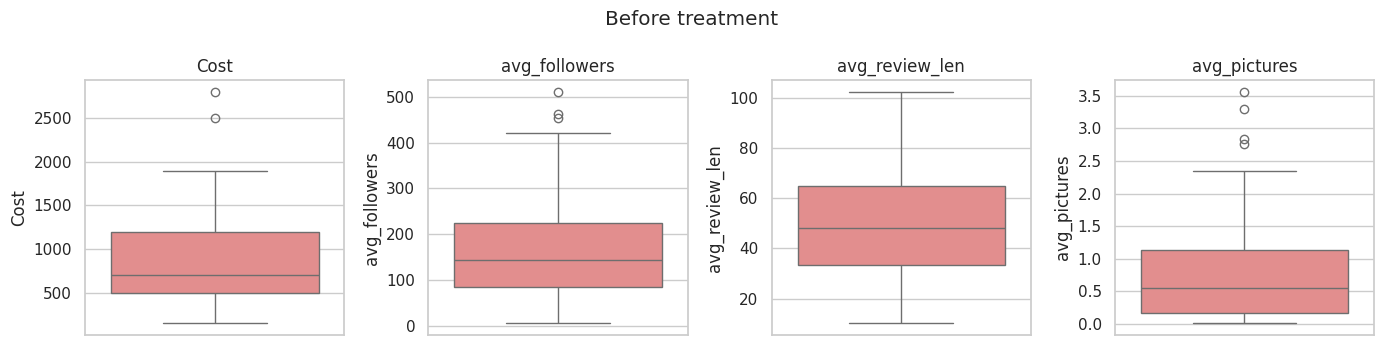


Skewness before -> after:
                before  after
Cost              1.17  -0.39
avg_followers     0.87  -1.20
avg_review_len    0.26  -0.64
avg_pictures      1.56   0.65


In [38]:
# Handling Outliers & Outlier treatments
skew_cols = ['Cost', 'avg_followers', 'avg_review_len', 'avg_pictures']   # n_reviews is ~100 for every restaurant -> not informative
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
print("IQR outliers per feature (before treatment):")
print({c: iqr_outliers(rest_stats[c]) for c in skew_cols})
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5))
for ax, c in zip(axes, skew_cols):
    sns.boxplot(y=rest_stats[c], ax=ax, color='lightcoral'); ax.set_title(c)
plt.suptitle('Before treatment'); plt.tight_layout(); plt.show()
# Treatment: log1p (compresses long right tail, keeps the premium/celebrity restaurants) + winsorise at 1st/99th percentile
for c in skew_cols:
    rest_stats['log_' + c] = np.log1p(rest_stats[c])
    lo, hi = rest_stats['log_' + c].quantile([.01, .99])
    rest_stats['log_' + c] = rest_stats['log_' + c].clip(lo, hi)
print("\nSkewness before -> after:")
print(pd.DataFrame({'before': rest_stats[skew_cols].skew(),
                    'after': rest_stats[['log_' + c for c in skew_cols]].skew().set_axis(skew_cols)}).round(2))

##### What all outlier treatment techniques have you used and why did you use those techniques?
IQR rule detection found few outliers (2 for cost, 3 for followers, 4 for pictures). They are **real** (luxury restaurants and restaurants visited by highly-followed reviewers), and with just 100 restaurants deleting them would remove the most interesting segments. So we used **log1p transformation** (reduces skew: cost skew 1.17 -> -0.39, pictures 1.56 -> 0.65) followed by **winsorising at the 1st/99th percentile** to stop a single extreme restaurant dominating the distance-based clustering.

### 3. Categorical Encoding

In [39]:
# Encode your categorical columns
# Cuisine is multi-valued ("North Indian, Chinese"), so one-hot encode with MultiLabelBinarizer for the top cuisines.
TOP_CUISINES = list(cuisine_counts.head(6).index)
mlb = MultiLabelBinarizer(classes=TOP_CUISINES)
cuisine_flags = pd.DataFrame(mlb.fit_transform(rest_stats['cuisine_list'].apply(lambda l: [c for c in l if c in TOP_CUISINES])),
                             columns=['cuisine_' + c.replace(' ', '_').lower() for c in TOP_CUISINES], index=rest_stats.index)
print("Encoded cuisine flags:", list(cuisine_flags.columns))
display(cuisine_flags.sum().to_frame('restaurants'))

Encoded cuisine flags: ['cuisine_north_indian', 'cuisine_chinese', 'cuisine_continental', 'cuisine_biryani', 'cuisine_asian', 'cuisine_fast_food']


,restaurants
cuisine_north_indian,60
cuisine_chinese,41
cuisine_continental,21
cuisine_biryani,15
cuisine_asian,14
cuisine_fast_food,13


#### What all categorical encoding techniques have you used & why did you use those techniques?
Cuisines are multi-valued, so ordinary one-hot or label encoding does not work; **multi-label (multi-hot) encoding** with `MultiLabelBinarizer` was applied to the six most common cuisines (North Indian, Chinese, Continental, Biryani, Asian, Fast Food). Rare cuisines are ignored to avoid a very sparse matrix. The flags are used to **profile** the clusters; `n_cuisines` and `n_collections` are numeric counts derived from the multi-valued text columns.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [40]:
# Expand Contraction
CONTRACTIONS = {"won't": "will not", "can't": "can not", "n't": " not", "'re": " are", "'s": " is", "'d": " would",
                "'ll": " will", "'ve": " have", "'m": " am"}
def expand_contractions(text):
    text = text.replace("’", "'")                          # curly apostrophes -> straight
    for pat, rep in CONTRACTIONS.items():
        text = text.replace(pat, rep)
    return text
rev['text_work'] = rev['Review'].apply(expand_contractions)
print(rev['text_work'].iloc[2][:200])

A must try.. great food great ambience. Thnx for the service by Pradeep and Subroto. My personal recommendation is Penne Alfredo Pasta:) ....... Also the music in the background is amazing.


#### 2. Lower Casing

In [41]:
# Lower Casing
rev['text_work'] = rev['text_work'].str.lower()
print(rev['text_work'].iloc[2][:200])

a must try.. great food great ambience. thnx for the service by pradeep and subroto. my personal recommendation is penne alfredo pasta:) ....... also the music in the background is amazing.


#### 3. Removing Punctuations

In [42]:
# Remove Punctuations
rev['text_work'] = rev['text_work'].apply(lambda t: re.sub(r'[^\w\s]', ' ', t))   # keep letters/digits/underscore only
print(rev['text_work'].iloc[2][:200])

a must try   great food great ambience  thnx for the service by pradeep and subroto  my personal recommendation is penne alfredo pasta           also the music in the background is amazing 


#### 4. Removing URLs & Removing words and digits contain digits.

In [43]:
# Remove URLs & Remove words and digits contain digits
rev['text_work'] = rev['Review'].apply(lambda t: re.sub(r'http\S+|www\.\S+', ' ', t))   # URLs removed from the raw text first
rev['text_work'] = (rev['text_work'].apply(expand_contractions).str.lower()
                    .apply(lambda t: re.sub(r'[^\w\s]', ' ', t))                       # re-apply steps 1-3 on URL-free text
                    .apply(lambda t: re.sub(r'\b\w*\d\w*\b', ' ', t)))                 # words containing digits
print(rev['text_work'].iloc[2][:200])

a must try   great food great ambience  thnx for the service by pradeep and subroto  my personal recommendation is penne alfredo pasta           also the music in the background is amazing 


#### 5. Removing Stopwords & Removing White spaces
Negations (*not, no, nor, never*) are **kept** because 'not good' and 'good' have opposite sentiment.

In [44]:
# Remove Stopwords
# keep negations: "not good" and "good" mean opposite things
STOPWORDS = set(ENGLISH_STOP_WORDS) - {'not', 'no', 'nor', 'never'}
rev['text_work'] = rev['text_work'].apply(lambda t: ' '.join(w for w in t.split() if w not in STOPWORDS))
print(rev['text_work'].iloc[2][:200])

try great food great ambience thnx service pradeep subroto personal recommendation penne alfredo pasta music background amazing


In [45]:
# Remove White spaces
rev['text_work'] = rev['text_work'].apply(lambda t: re.sub(r'\s+', ' ', t).strip())
print(rev['text_work'].iloc[2][:200])

try great food great ambience thnx service pradeep subroto personal recommendation penne alfredo pasta music background amazing


#### 6. Rephrase Text

In [46]:
# Rephrase Text
# Normalise elongated words ("sooo goood" -> "soo good") and a few common slang / spelling variants.
SLANG = {'ok': 'okay', 'thnx': 'thanks', 'thx': 'thanks', 'gud': 'good', 'nic': 'nice', 'awsome': 'awesome',
         'amazin': 'amazing', 'yummy': 'tasty', 'yum': 'tasty', 'delicious': 'tasty', 'luv': 'love'}
def rephrase(text):
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)              # 3+ repeated letters -> 2
    return ' '.join(SLANG.get(w, w) for w in text.split())
rev['text_work'] = rev['text_work'].apply(rephrase)
print(rev['text_work'].iloc[2][:200])

try great food great ambience thanks service pradeep subroto personal recommendation penne alfredo pasta music background amazing


#### 7. Tokenization

In [47]:
# Tokenization
rev['tokens'] = rev['text_work'].apply(lambda t: re.findall(r"[a-z]+", t))
print(rev['tokens'].iloc[2][:20])
print("Average tokens per review:", round(rev['tokens'].str.len().mean(), 1))

['try', 'great', 'food', 'great', 'ambience', 'thanks', 'service', 'pradeep', 'subroto', 'personal', 'recommendation', 'penne', 'alfredo', 'pasta', 'music', 'background', 'amazing']
Average tokens per review: 25.6


#### 8. Text Normalization

In [48]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)
def light_lemma(w):
    """Fallback lemmatiser (plural handling) used when NLTK WordNet data cannot be downloaded."""
    if len(w) > 4 and w.endswith('ies'): return w[:-3] + 'y'
    if len(w) > 4 and w.endswith(('ches', 'shes', 'xes', 'sses')): return w[:-2]
    if len(w) > 3 and w.endswith('s') and not w.endswith(('ss', 'us', 'is')): return w[:-1]
    return w
try:                                                         # preferred: WordNet lemmatizer (available in Colab)
    import nltk
    nltk.download('wordnet', quiet=True); nltk.download('omw-1.4', quiet=True)
    from nltk.stem import WordNetLemmatizer
    _wnl = WordNetLemmatizer(); _wnl.lemmatize('foods')    # raises LookupError if data is missing
    lemmatize, LEMMATIZER = _wnl.lemmatize, 'NLTK WordNetLemmatizer'
except Exception:
    lemmatize, LEMMATIZER = light_lemma, 'rule-based plural lemmatizer (fallback)'
rev['lemmas'] = rev['tokens'].apply(lambda toks: [lemmatize(w) for w in toks])
rev['clean_text'] = rev['lemmas'].apply(' '.join)
print("Lemmatizer used:", LEMMATIZER)
print("Before:", rev['text_work'].iloc[2][:120]); print("After :", rev['clean_text'].iloc[2][:120])

Lemmatizer used: NLTK WordNetLemmatizer
Before: try great food great ambience thanks service pradeep subroto personal recommendation penne alfredo pasta music backgroun
After : try great food great ambience thanks service pradeep subroto personal recommendation penne alfredo pasta music backgroun


##### Which text normalization technique have you used and why?
**Lemmatization** (WordNet lemmatizer when NLTK data is available, otherwise a rule-based plural lemmatizer) instead of stemming: it returns real words ('dishes' -> 'dish', 'foods' -> 'food'), which keeps the top-word charts and model features readable, while stemming would give truncated tokens ('servic').

#### 9. Part of speech tagging

In [49]:
# POS Taging
try:
    import nltk
    for pkg in ['averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
        nltk.download(pkg, quiet=True)
    sample_tokens = rev['tokens'].iloc[2][:12]
    print(nltk.pos_tag(sample_tokens))
    sample_pos = Counter(tag for toks in rev['tokens'].head(300) for _, tag in nltk.pos_tag(toks))
    print("\nMost common POS tags in 300 reviews:", sample_pos.most_common(5))
except Exception as e:
    print("POS tagger data not available in this environment, skipping (not used by the models). Reason:", type(e).__name__)

[('try', 'VB'), ('great', 'JJ'), ('food', 'NN'), ('great', 'JJ'), ('ambience', 'NN'), ('thanks', 'NNS'), ('service', 'NN'), ('pradeep', 'VBP'), ('subroto', 'JJ'), ('personal', 'JJ'), ('recommendation', 'NN'), ('penne', 'NN')]

Most common POS tags in 300 reviews: [('NN', 2863), ('JJ', 1647), ('NNS', 557), ('RB', 468), ('VBD', 299)]


#### 10. Text Vectorization

In [50]:
# Vectorizing Text
tfidf_demo = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=5000, sublinear_tf=True)
X_demo = tfidf_demo.fit_transform(rev['clean_text'])
print("TF-IDF matrix shape:", X_demo.shape, "| sparsity:", f"{1 - X_demo.nnz / np.prod(X_demo.shape):.2%}")
mean_tfidf = pd.Series(np.asarray(X_demo.mean(axis=0)).ravel(), index=tfidf_demo.get_feature_names_out())
print("Highest average TF-IDF terms:", list(mean_tfidf.nlargest(10).index))

TF-IDF matrix shape: (9961, 5000) | sparsity: 99.49%
Highest average TF-IDF terms: ['good', 'food', 'not', 'place', 'service', 'nice', 'taste', 'chicken', 'time', 'great']


##### Which text vectorization technique have you used and why?
**TF-IDF with unigrams + bigrams** (sublinear term frequency, min_df = 3-5, up to 5,000-8,000 features). TF-IDF down-weights generic words ('food', 'place') that appear in every review and highlights discriminative ones; bigrams capture phrases like 'not good' or 'highly recommended'. It is also sparse, fast and works very well with linear models.

### 4. Feature Manipulation & Selection
#### 1. Feature Manipulation

In [51]:
# Manipulate Features to minimize feature correlation and create new features
# NEW FEATURE: review sentiment. A TF-IDF + Logistic Regression model learns what positive / negative language looks like from
# the star ratings; we use OUT-OF-FOLD probabilities (5-fold) so no review is scored by a model that saw its own label.
sent_pipe = Pipeline([('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=8000, sublinear_tf=True)),
                      ('clf', LogisticRegression(max_iter=2000, class_weight='balanced', C=2.0, random_state=RANDOM_STATE))])
oof = cross_val_predict(sent_pipe, rev['clean_text'], rev['sentiment_label'].astype(str),
                        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE), method='predict_proba')
classes = sorted(rev['sentiment_label'].astype(str).unique())            # ['negative','neutral','positive']
proba = pd.DataFrame(oof, columns=classes, index=rev.index)
rev['sentiment_score'] = proba['positive'] - proba['negative']          # -1 (very negative) ... +1 (very positive)
rev['pred_label'] = proba.idxmax(axis=1)

sent_agg = rev.groupby('Restaurant').agg(avg_sentiment=('sentiment_score', 'mean'),
                                         pct_positive=('pred_label', lambda s: (s == 'positive').mean()),
                                         pct_negative=('pred_label', lambda s: (s == 'negative').mean())).reset_index().rename(columns={'Restaurant': 'Name'})
rest_model = rest_stats.merge(sent_agg, on='Name').reset_index(drop=True)
rest_model = pd.concat([rest_model, cuisine_flags.reset_index(drop=True)], axis=1)
print("Out-of-fold accuracy of the sentiment model:", round(accuracy_score(rev['sentiment_label'].astype(str), rev['pred_label']), 3))
print("Correlation avg_rating vs avg_sentiment:", round(rest_model['avg_rating'].corr(rest_model['avg_sentiment']), 3))
display(rest_model[['Name', 'avg_rating', 'avg_sentiment', 'pct_positive', 'pct_negative']].head())

Out-of-fold accuracy of the sentiment model: 0.81
Correlation avg_rating vs avg_sentiment: 0.972


,Name,avg_rating,avg_sentiment,pct_positive,pct_negative
0,Beyond Flavours,4.28,0.596023,0.81,0.13
1,Paradise,4.70,0.768134,0.94,0.04
2,Flechazo,4.66,0.755557,0.88,0.04
3,Shah Ghouse Hotel & Restaurant,3.21,-0.022046,0.44,0.41
4,Over The Moon Brew Company,4.34,0.679539,0.85,0.10


**New features created:** `avg_sentiment`, `pct_positive`, `pct_negative` (from the sentiment model), `n_cuisines`, `n_collections`, `open_hours`, `pct_with_pictures`, `rating_std` and the log-transformed versions of the skewed variables. The out-of-fold scoring avoids data leakage. The sentiment score correlates r = 0.97 with the average star rating, so the text signal confirms the ratings (and the two are redundant for clustering).

#### 2. Feature Selection

In [52]:
# Select your features wisely to avoid overfitting
candidates = ['log_Cost', 'avg_rating', 'avg_sentiment', 'pct_positive', 'pct_negative', 'rating_std', 'log_avg_followers',
              'avg_reviewer_reviews', 'avg_pictures', 'log_avg_review_len', 'n_cuisines', 'n_collections', 'open_hours'] + list(cuisine_flags.columns)
# Step 1 - drop one feature of every pair with |Spearman r| > 0.85 (keep the first, i.e. the more interpretable one)
cm = rest_model[candidates].corr(method='spearman').abs()
drop = set()
for i, a in enumerate(cm.columns):
    for b in cm.columns[i + 1:]:
        if a not in drop and b not in drop and cm.loc[a, b] > 0.85:
            drop.add(b); print(f"|r| = {cm.loc[a, b]:.2f} between {a} and {b} -> dropping {b}")
survivors = [c for c in candidates if c not in drop]

# Step 2 - with only ~100 restaurants, many weak features dilute the cluster structure (curse of dimensionality).
# Compare feature sets by the best K-Means silhouette over k = 2..8 and keep the one with the clearest separation.
core = ['log_Cost', 'avg_rating', 'log_avg_followers', 'avg_pictures', 'n_collections']          # price, quality, reviewer reach, engagement, curation
FEATURE_SETS = {'all survivors (' + str(len(survivors)) + ')': survivors,
                'core + cuisine flags': core + list(cuisine_flags.columns),
                'core + n_cuisines + open_hours': core + ['n_cuisines', 'open_hours'],
                'core (5)': core}
rows = []
for name, cols in FEATURE_SETS.items():
    Xs = StandardScaler().fit_transform(rest_model[cols])
    sc = {k: silhouette_score(Xs, KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(Xs)) for k in range(2, 9)}
    rows.append({'feature set': name, 'n_features': len(cols), 'best_k': max(sc, key=sc.get), 'best_silhouette': max(sc.values())})
display(pd.DataFrame(rows).round(3))
FEATURES = core                                       # selected: highest separation and every feature is directly actionable
print("\nSelected clustering features:", FEATURES)
print("Used only for PROFILING the clusters (not for fitting):", ['n_cuisines', 'open_hours', 'avg_sentiment', 'pct_negative'] + list(cuisine_flags.columns))

|r| = 0.96 between avg_rating and avg_sentiment -> dropping avg_sentiment
|r| = 0.97 between avg_rating and pct_positive -> dropping pct_positive
|r| = 0.91 between avg_rating and pct_negative -> dropping pct_negative
|r| = 0.86 between avg_pictures and log_avg_review_len -> dropping log_avg_review_len


,feature set,n_features,best_k,best_silhouette
0,all survivors (15),15,6,0.169
1,core + cuisine flags,11,8,0.228
2,core + n_cuisines + open_hours,7,2,0.214
3,core (5),5,3,0.277



Selected clustering features: ['log_Cost', 'avg_rating', 'log_avg_followers', 'avg_pictures', 'n_collections']
Used only for PROFILING the clusters (not for fitting): ['n_cuisines', 'open_hours', 'avg_sentiment', 'pct_negative', 'cuisine_north_indian', 'cuisine_chinese', 'cuisine_continental', 'cuisine_biryani', 'cuisine_asian', 'cuisine_fast_food']


##### What all feature selection methods have you used  and why did you use those techniques?
1. **Correlation filter** (|Spearman r| > 0.85): removed `avg_sentiment`, `pct_positive`, `pct_negative` (all ~0.9+ with average rating) and `log_avg_review_len` (0.86 with pictures) to avoid double-counting the same information in a distance-based algorithm.
2. **Feature-set comparison using silhouette:** with only 100 restaurants, adding many weak features (cuisine flags, opening hours, number of cuisines) makes the clusters blurrier (best silhouette 0.17 with 15 features, 0.23 with core + cuisine flags, 0.28 with the 5 core features), a clear case of the curse of dimensionality. The less informative features are used afterwards to *profile* the clusters.

##### Which all features you found important and why?
`log_Cost` (price tier), `avg_rating` (quality), `log_avg_followers` (reviewer reach / critics), `avg_pictures` (customer engagement) and `n_collections` (Zomato curation / visibility). Each is directly actionable for Zomato, easy to explain to stakeholders and weakly correlated with the others.

### 5. Data Transformation
#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [53]:
# Transform Your data
# Log transformation was already applied to the right-skewed variables (see outlier section). Verify the result:
chk = rest_model[FEATURES].skew().abs().sort_values(ascending=False)
print("Largest remaining absolute skewness values:")
print(chk.head(5).round(2))

Largest remaining absolute skewness values:
n_collections        1.77
avg_pictures         1.56
log_avg_followers    1.20
log_Cost             0.39
avg_rating           0.28
dtype: float64


Yes - the right-skewed variables (cost, reviewer followers, review length, pictures) were **log1p-transformed**, because K-Means and Gaussian Mixture assume roughly compact, symmetric groups and are sensitive to long tails. After the transformation, the skewness of the cost variable fell from 1.17 to -0.39. `n_collections` (skew 1.8) is a small count variable and was left as is.

### 6. Data Scaling

In [54]:
# Scaling your data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(rest_model[FEATURES])
X_scaled_df = pd.DataFrame(X_scaled, columns=FEATURES)
print("Mean of scaled features (should be ~0):", X_scaled.mean().round(3), "| std:", X_scaled.std().round(3))

Mean of scaled features (should be ~0): 0.0 | std: 1.0


##### Which method have you used to scale you data and why?
**StandardScaler (z-score).** All three algorithms are distance- or variance-based, so features such as cost (hundreds) and rating (1-5) must be on the same scale. Standardisation is preferred over Min-Max because the log-transformed features still have a few extreme values which would compress the Min-Max range.

### 7. Dimesionality Reduction
##### Do you think that dimensionality reduction is needed? Explain Why?

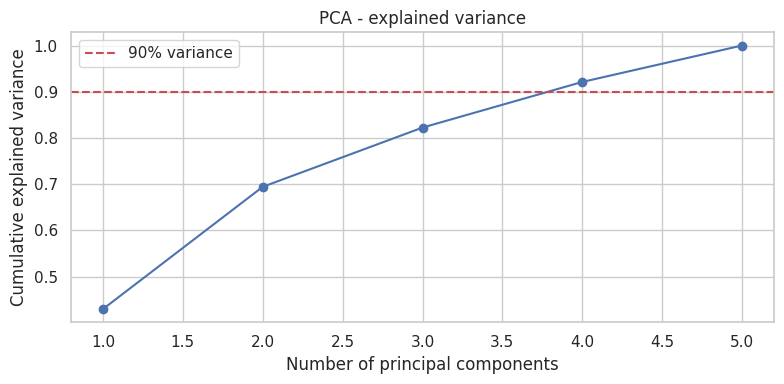

Components needed for 90% variance: 4 of 5
Variance captured by the 2 plotting components: 0.694


In [55]:
# Dimensionality Reduction (If needed)
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum = np.cumsum(pca_full.explained_variance_ratio_)
plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum) + 1), cum, marker='o')
plt.axhline(0.9, color='r', ls='--', label='90% variance')
plt.xlabel('Number of principal components'); plt.ylabel('Cumulative explained variance'); plt.title('PCA - explained variance'); plt.legend()
plt.tight_layout(); plt.show()
print("Components needed for 90% variance:", int(np.argmax(cum >= 0.9) + 1), "of", len(FEATURES))
pca2 = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca2 = pca2.fit_transform(X_scaled)           # 2-D projection used ONLY for plotting the clusters
print("Variance captured by the 2 plotting components:", pca2.explained_variance_ratio_.sum().round(3))

Not for the clustering itself: we deliberately reduced the data to only 5 interpretable features by feature selection, and 4 of the 5 principal components are needed for 90% of the variance, so PCA would not simplify things.
##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)
**PCA to 2 components, used only for visualising the clusters** (it captures 69% of the variance: PC1 43%, PC2 26%). The models are trained on the full 5 standardised features.

### 8. Data Splitting

In [56]:
# Split your data to train and test. Choose Splitting ratio wisely.
# Clustering is unsupervised (no target) so it uses all restaurants. The supporting sentiment classifier
# (rating -> sentiment from text) is evaluated honestly on a stratified hold-out set.
X_tr, X_te, y_tr, y_te = train_test_split(rev['clean_text'], rev['sentiment_label'].astype(str),
                                          test_size=0.2, stratify=rev['sentiment_label'].astype(str), random_state=RANDOM_STATE)
print("Train:", len(X_tr), "| Test:", len(X_te))

Train: 7968 | Test: 1993


##### What data splitting ratio have you used and why?
**80 / 20 stratified split** for the supporting sentiment classifier (7,968 train / 1,993 test). Stratification keeps the positive/neutral/negative proportions identical in both sets. The clustering models are unsupervised (no target), so they use all 100 restaurants; they are validated with internal metrics and bootstrap stability instead of a train/test split.

### 9. Handling Imbalanced Dataset
##### Do you think the dataset is imbalanced? Explain Why.

In [57]:
# Handling Imbalanced Dataset (If needed)
print(y_tr.value_counts(normalize=True).round(3))
hold = sent_pipe.fit(X_tr, y_tr)           # class_weight='balanced' re-weights the minority classes during training
pred = hold.predict(X_te)
print(f"\nHold-out accuracy: {accuracy_score(y_te, pred):.3f} | macro-F1: {f1_score(y_te, pred, average='macro'):.3f}")
print(classification_report(y_te, pred))

sentiment_label
positive    0.630
negative    0.246
neutral     0.124
Name: proportion, dtype: float64

Hold-out accuracy: 0.805 | macro-F1: 0.706
              precision    recall  f1-score   support

    negative       0.81      0.81      0.81       490
     neutral       0.37      0.48      0.41       248
    positive       0.93      0.87      0.90      1255

    accuracy                           0.81      1993
   macro avg       0.70      0.72      0.71      1993
weighted avg       0.83      0.81      0.81      1993



Yes, the **sentiment classes** are imbalanced: 63% positive, 25% negative and only 12% neutral. A model that always predicts 'positive' would already reach 63% accuracy.
##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)
`class_weight='balanced'` in Logistic Regression: it increases the penalty for mistakes on minority classes without discarding data or creating synthetic text (SMOTE is awkward on sparse TF-IDF). Hold-out accuracy is 0.80 and macro-F1 0.70 (negative F1 0.80, positive 0.90, neutral 0.41). Neutral reviews are inherently ambiguous, which is why they are the hardest class; this is acceptable because we aggregate scores over ~100 reviews per restaurant, where individual errors average out.

## ***7. ML Model Implementation***

Three unsupervised algorithms are implemented: **K-Means, Hierarchical (Agglomerative) clustering and Gaussian Mixture**. Because there are no labels, performance is measured with three internal metrics: **Silhouette** (higher is better, range -1 to 1), **Davies-Bouldin** (lower is better) and **Calinski-Harabasz** (higher is better). 'Cross-validation' for clustering is replaced by a **bootstrap stability test** (Adjusted Rand Index between clusters fitted on resampled data), and hyper-parameter tuning is a grid search that only accepts *actionable* segmentations (at least 3 clusters, none smaller than 10% of the restaurants).

### ML Model - 1 : K-Means

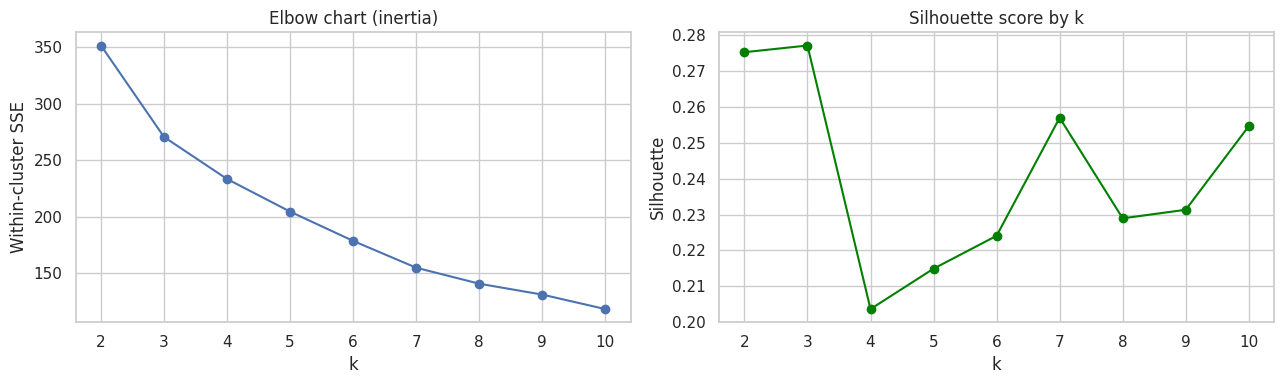

 k  inertia  silhouette
 2    351.7       0.275
 3    270.8       0.277
 4    233.5       0.204
 5    204.7       0.215
 6    178.7       0.224
 7    155.0       0.257
 8    140.8       0.229
 9    131.2       0.231
10    118.4       0.255


In [58]:
# ML Model - 1 : K-Means  - choose k with the Elbow method and silhouette score
def score_labels(X, labels):
    """Return the three internal clustering metrics for a labelling."""
    return {'silhouette': silhouette_score(X, labels), 'davies_bouldin': davies_bouldin_score(X, labels),
            'calinski_harabasz': calinski_harabasz_score(X, labels)}
# Business rule for an *actionable* segmentation: at least 3 segments and no segment below 10% of the restaurants
# (this stops a grid search from "winning" with a lopsided split such as 80 restaurants in one cluster and 6 in another).
MIN_K, MIN_SHARE = 3, 0.10
def is_valid(labels):
    share = pd.Series(labels).value_counts(normalize=True)
    return len(share) >= MIN_K and share.min() >= MIN_SHARE
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertia.append(km_k.inertia_); sil.append(silhouette_score(X_scaled, km_k.labels_))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(ks, inertia, marker='o'); axes[0].set_title('Elbow chart (inertia)'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Within-cluster SSE')
axes[1].plot(ks, sil, marker='o', color='green'); axes[1].set_title('Silhouette score by k'); axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette')
plt.tight_layout(); plt.show()
print(pd.DataFrame({'k': list(ks), 'inertia': np.round(inertia, 1), 'silhouette': np.round(sil, 3)}).to_string(index=False))

In [59]:
# ML Model - 1 Implementation  (k chosen from the elbow + silhouette charts above)
K_BASE = 3
km1 = KMeans(n_clusters=K_BASE, n_init=10, random_state=RANDOM_STATE)    # Fit the Algorithm
km1.fit(X_scaled)
km1_labels = km1.predict(X_scaled)                                       # Predict on the model
km1_scores = score_labels(X_scaled, km1_labels)
print("Cluster sizes:", dict(pd.Series(km1_labels).value_counts().sort_index()))
print({k: round(v, 3) for k, v in km1_scores.items()})

Cluster sizes: {0: np.int64(38), 1: np.int64(15), 2: np.int64(47)}
{'silhouette': np.float64(0.277), 'davies_bouldin': np.float64(1.221), 'calinski_harabasz': np.float64(41.059)}


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.
**K-Means** assigns every restaurant to the nearest of k centroids and iteratively moves the centroids to minimise the within-cluster sum of squares. It is fast, simple and easy to explain. **How k was chosen:** the elbow chart bends gently around k = 3-4 and the silhouette score is highest at k = 2-3 at k = 2 and 3 (0.275 and 0.277) before dropping to 0.20 at k = 4, so **k = 3** is the most defensible choice. Baseline scores: **silhouette 0.277, Davies-Bouldin 1.221, Calinski-Harabasz 41.1**, cluster sizes 38 / 15 / 47.

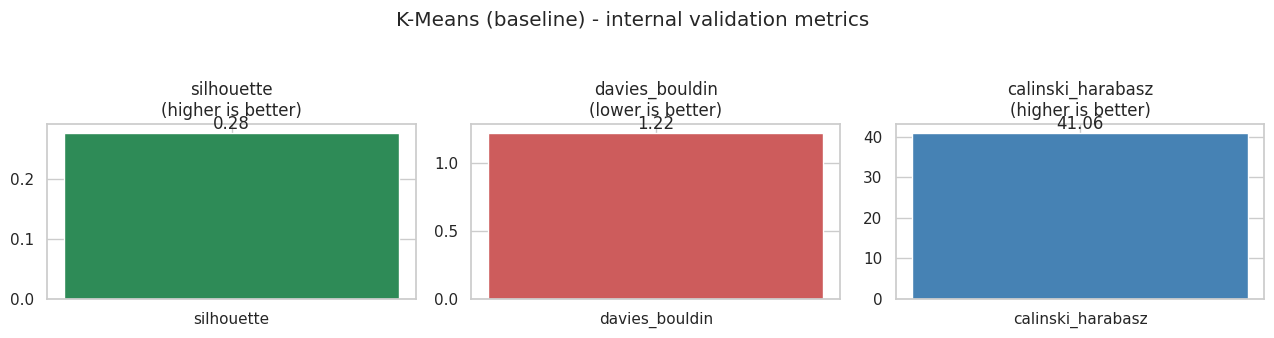

In [60]:
# Visualizing evaluation Metric Score chart
def plot_scores(scores, title):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
    for ax, (name, val), col in zip(axes, scores.items(), ['seagreen', 'indianred', 'steelblue']):
        ax.bar([name], [val], color=col); ax.set_title(f'{name}\n({"higher" if name != "davies_bouldin" else "lower"} is better)')
        ax.text(0, val, f'{val:.2f}', ha='center', va='bottom')
    plt.suptitle(title, y=1.05); plt.tight_layout(); plt.show()
plot_scores(km1_scores, 'K-Means (baseline) - internal validation metrics')

#### 2. Cross- Validation & Hyperparameter Tuning

In [61]:
# ML Model - 1 Implementation with hyperparameter optimization (grid search on k, init, n_init, algorithm; only valid segmentations kept)
rows = []
for k in range(MIN_K, 9):
    for init in ['k-means++', 'random']:
        for n_init in [10, 30]:
            for algo in ['lloyd', 'elkan']:
                m = KMeans(n_clusters=k, init=init, n_init=n_init, algorithm=algo, random_state=RANDOM_STATE).fit(X_scaled)
                if is_valid(m.labels_):
                    rows.append({'k': k, 'init': init, 'n_init': n_init, 'algorithm': algo, **score_labels(X_scaled, m.labels_)})
km_grid = pd.DataFrame(rows).sort_values('silhouette', ascending=False)
display(km_grid.head(5).round(3))
best = km_grid.iloc[0]
km2 = KMeans(n_clusters=int(best['k']), init=best['init'], n_init=int(best['n_init']), algorithm=best['algorithm'], random_state=RANDOM_STATE).fit(X_scaled)
km2_labels = km2.predict(X_scaled)
km2_scores = score_labels(X_scaled, km2_labels)
print("Tuned K-Means ->", {k: round(v, 3) for k, v in km2_scores.items()}, "| k =", km2.n_clusters)

,k,init,n_init,algorithm,silhouette,davies_bouldin,calinski_harabasz
0,3,k-means++,10,lloyd,0.277,1.221,41.059
1,3,k-means++,10,elkan,0.277,1.221,41.059
2,3,k-means++,30,lloyd,0.277,1.221,41.059
3,3,k-means++,30,elkan,0.277,1.221,41.059
4,3,random,10,lloyd,0.277,1.221,41.059


Tuned K-Means -> {'silhouette': np.float64(0.277), 'davies_bouldin': np.float64(1.221), 'calinski_harabasz': np.float64(41.059)} | k = 3


Bootstrap stability (ARI, 1 = identical clusters) - baseline k=3: 0.76 +/- 0.17 | tuned k=3: 0.76 +/- 0.17


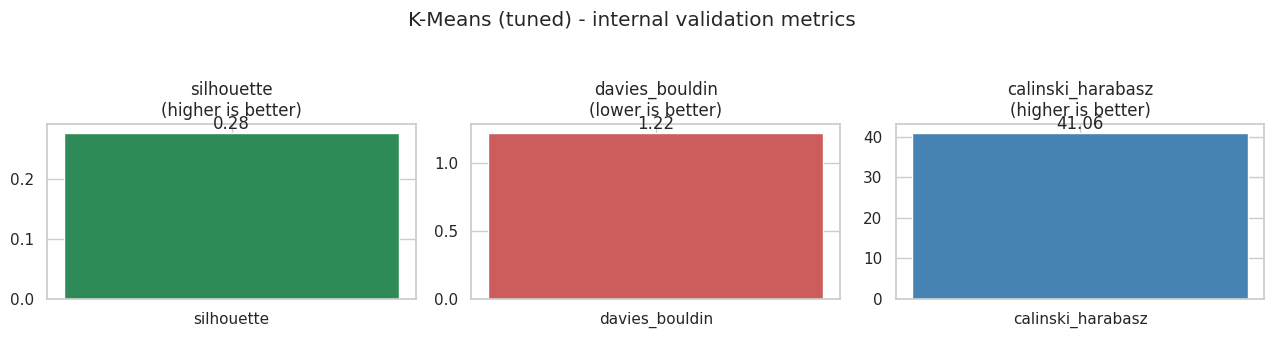

In [62]:
# Cross-validation substitute for clustering: bootstrap stability (Adjusted Rand Index between fits on resampled data)
def stability(make_model, X, n_boot=30):
    base = make_model().fit_predict(X); aris = []
    rng = np.random.RandomState(RANDOM_STATE)
    for _ in range(n_boot):
        idx = rng.choice(len(X), len(X), replace=True)
        m = make_model().fit(X[idx])
        aris.append(adjusted_rand_score(base, m.predict(X) if hasattr(m, 'predict') else base))
    return np.mean(aris), np.std(aris)
mean_ari_base, sd_base = stability(lambda: KMeans(n_clusters=K_BASE, n_init=10, random_state=RANDOM_STATE), X_scaled)
mean_ari_tuned, sd_tuned = stability(lambda: KMeans(n_clusters=km2.n_clusters, n_init=10, random_state=RANDOM_STATE), X_scaled)
print(f"Bootstrap stability (ARI, 1 = identical clusters) - baseline k={K_BASE}: {mean_ari_base:.2f} +/- {sd_base:.2f} | tuned k={km2.n_clusters}: {mean_ari_tuned:.2f} +/- {sd_tuned:.2f}")
plot_scores(km2_scores, 'K-Means (tuned) - internal validation metrics')

##### Which hyperparameter optimization technique have you used and why?
**Grid search** over k (3-8), `init` (k-means++ / random), `n_init` (10 / 30) and `algorithm` (lloyd / elkan), scored by silhouette. The search space is tiny and each fit takes milliseconds, so an exhaustive grid is cheaper and more reliable than random or Bayesian search. **Cross-validation substitute:** 30 bootstrap resamples gave a mean Adjusted Rand Index of **0.76 +/- 0.17**, i.e. the segments are reasonably stable even with only 100 restaurants.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.
No - the tuned K-Means has exactly the same scores (silhouette 0.277, DB 1.221, CH 41.1). This is a good sign: K-Means with k-means++ and k = 3 already finds the global optimum on this small, low-dimensional dataset, so extra tuning cannot improve it.

### ML Model - 2 : Hierarchical (Agglomerative) clustering

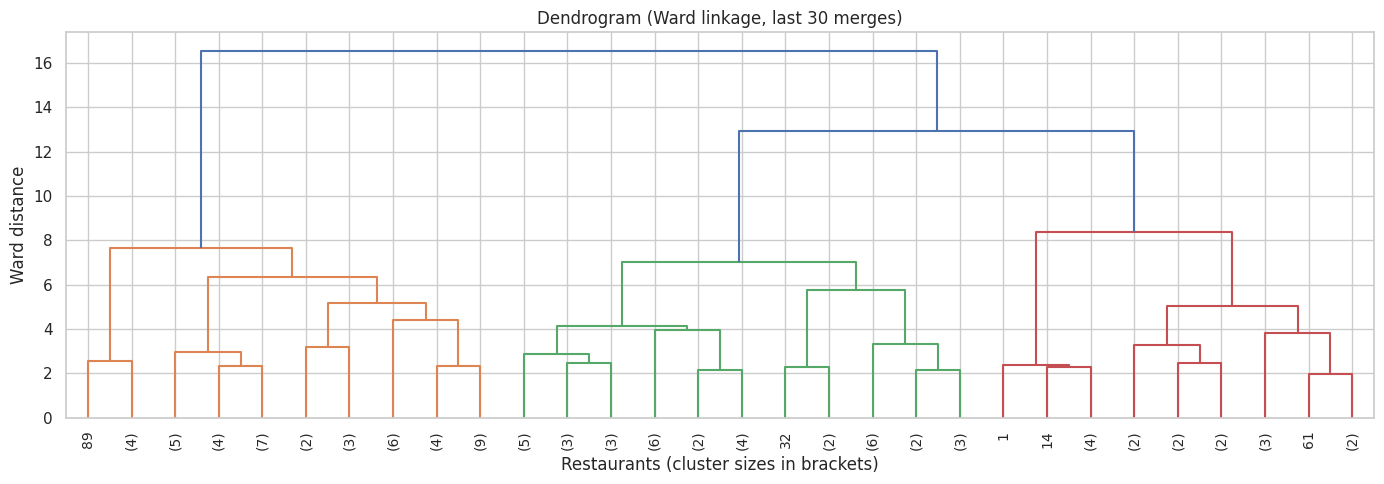

In [63]:
# ML Model - 2 : Hierarchical (Agglomerative) clustering - dendrogram
Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode='lastp', p=30, show_leaf_counts=True, leaf_rotation=90)
plt.title('Dendrogram (Ward linkage, last 30 merges)'); plt.xlabel('Restaurants (cluster sizes in brackets)'); plt.ylabel('Ward distance')
plt.tight_layout(); plt.show()

Cluster sizes: {0: np.int64(18), 1: np.int64(45), 2: np.int64(37)}
{'silhouette': np.float64(0.262), 'davies_bouldin': np.float64(1.286), 'calinski_harabasz': np.float64(38.328)}


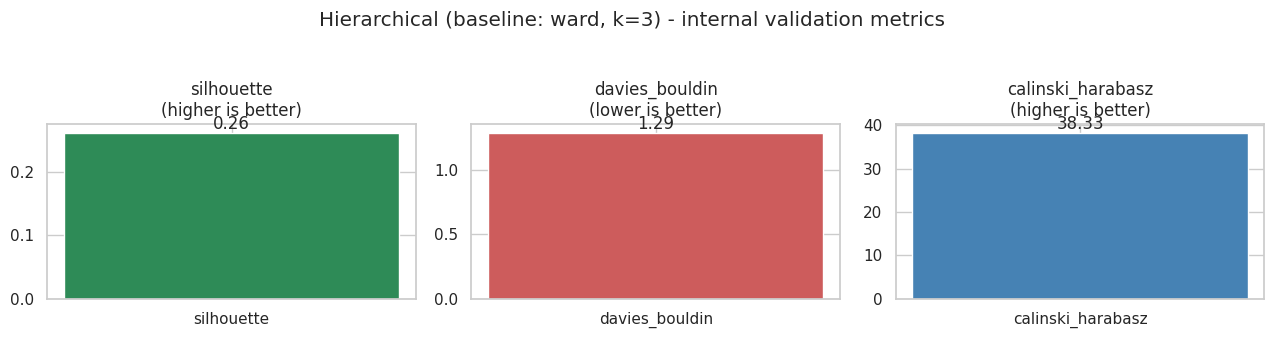

In [64]:
# ML Model - 2 Implementation
hc1 = AgglomerativeClustering(n_clusters=K_BASE, linkage='ward')         # Fit the Algorithm
hc1_labels = hc1.fit_predict(X_scaled)                                    # Predict on the model
hc1_scores = score_labels(X_scaled, hc1_labels)
print("Cluster sizes:", dict(pd.Series(hc1_labels).value_counts().sort_index()))
print({k: round(v, 3) for k, v in hc1_scores.items()})
plot_scores(hc1_scores, 'Hierarchical (baseline: ward, k=3) - internal validation metrics')

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.
**Agglomerative clustering with Ward linkage** starts with every restaurant as its own cluster and repeatedly merges the two clusters that increase within-cluster variance the least. In the dendrogram, the last two merges (Ward distance about 16.5 and 12.9) are much taller than every merge below about 8, so cutting at a distance of about 10 gives **k = 3**. It does not require random initialisation and gives a hierarchy of restaurant groups. Baseline: **silhouette 0.262, Davies-Bouldin 1.286, Calinski-Harabasz 38.3**; cluster sizes 18 / 45 / 37.

#### 2. Cross- Validation & Hyperparameter Tuning

,linkage,k,silhouette,davies_bouldin,calinski_harabasz
0,ward,3,0.262,1.286,38.328
1,complete,3,0.240,1.246,34.079


Tuned hierarchical -> {'silhouette': np.float64(0.262), 'davies_bouldin': np.float64(1.286), 'calinski_harabasz': np.float64(38.328)} | linkage = ward | k = 3
Cluster sizes: {0: np.int64(18), 1: np.int64(45), 2: np.int64(37)}


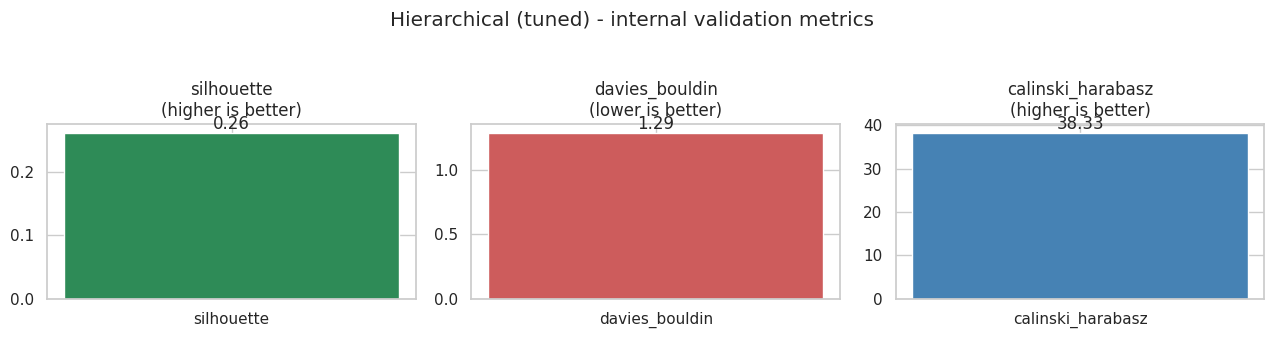

In [65]:
# ML Model - 2 with hyperparameter optimisation (grid over linkage x k)
rows = []
for link in ['ward', 'complete', 'average']:
    for k in range(MIN_K, 9):
        lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(X_scaled)
        if is_valid(lab):
            rows.append({'linkage': link, 'k': k, **score_labels(X_scaled, lab)})
hc_grid = pd.DataFrame(rows).sort_values('silhouette', ascending=False)
display(hc_grid.head(5).round(3))
bh = hc_grid.iloc[0]
hc2 = AgglomerativeClustering(n_clusters=int(bh['k']), linkage=bh['linkage'])
hc2_labels = hc2.fit_predict(X_scaled)
hc2_scores = score_labels(X_scaled, hc2_labels)
print("Tuned hierarchical ->", {k: round(v, 3) for k, v in hc2_scores.items()}, "| linkage =", bh['linkage'], "| k =", int(bh['k']))
print("Cluster sizes:", dict(pd.Series(hc2_labels).value_counts().sort_index()))
plot_scores(hc2_scores, 'Hierarchical (tuned) - internal validation metrics')

##### Which hyperparameter optimization technique have you used and why?
Grid search over linkage (ward / complete / average) x k (3-8), keeping only valid segmentations. `average` linkage scored a higher silhouette at k = 2-3 *only* by isolating a few outlier restaurants in tiny clusters (e.g. 97 vs 3 restaurants at k = 2), which is why such splits are rejected by the 10% minimum-size rule.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.
No - Ward linkage with k = 3 remains the best valid configuration (silhouette 0.262, DB 1.286, CH 38.3), so the tuned model equals the baseline. Hierarchical clustering is slightly behind K-Means on all three metrics, probably because its merges are irreversible (a restaurant mis-merged early cannot move later).

### ML Model - 3 : Gaussian Mixture Model (GMM)

Cluster sizes: {0: np.int64(15), 1: np.int64(30), 2: np.int64(55)}
{'silhouette': np.float64(0.219), 'davies_bouldin': np.float64(1.494), 'calinski_harabasz': np.float64(26.475)}


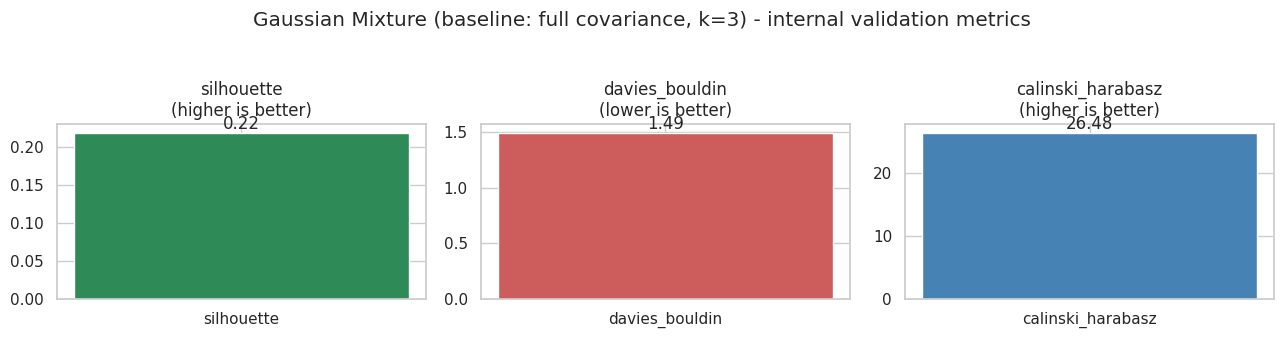

In [66]:
# ML Model - 3 : Gaussian Mixture Model (soft / probabilistic clustering)
gmm1 = GaussianMixture(n_components=K_BASE, covariance_type='full', random_state=RANDOM_STATE)   # Fit the Algorithm
gmm1.fit(X_scaled)
gmm1_labels = gmm1.predict(X_scaled)                                                              # Predict on the model
gmm1_scores = score_labels(X_scaled, gmm1_labels)
print("Cluster sizes:", dict(pd.Series(gmm1_labels).value_counts().sort_index()))
print({k: round(v, 3) for k, v in gmm1_scores.items()})
plot_scores(gmm1_scores, 'Gaussian Mixture (baseline: full covariance, k=3) - internal validation metrics')

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.
A **Gaussian Mixture Model** assumes that the data come from a mix of k Gaussian distributions and fits them with the EM algorithm. Unlike K-Means it supports clusters of different sizes / shapes and gives every restaurant a *probability* of belonging to each segment (soft clustering), which is useful for borderline restaurants. Baseline (full covariance, k = 3): **silhouette 0.219, Davies-Bouldin 1.494, Calinski-Harabasz 26.5**; cluster sizes 15 / 30 / 55.

#### 2. Cross- Validation & Hyperparameter Tuning

,covariance,k,bic,silhouette,davies_bouldin,calinski_harabasz
3,spherical,3,1377.934,0.282,1.196,40.208
1,diag,3,835.301,0.140,1.876,20.659
0,full,3,871.917,0.100,2.379,16.115
2,diag,4,820.852,0.045,1.922,21.826


Tuned GMM -> {'silhouette': np.float64(0.282), 'davies_bouldin': np.float64(1.196), 'calinski_harabasz': np.float64(40.208)} | covariance = spherical | k = 3


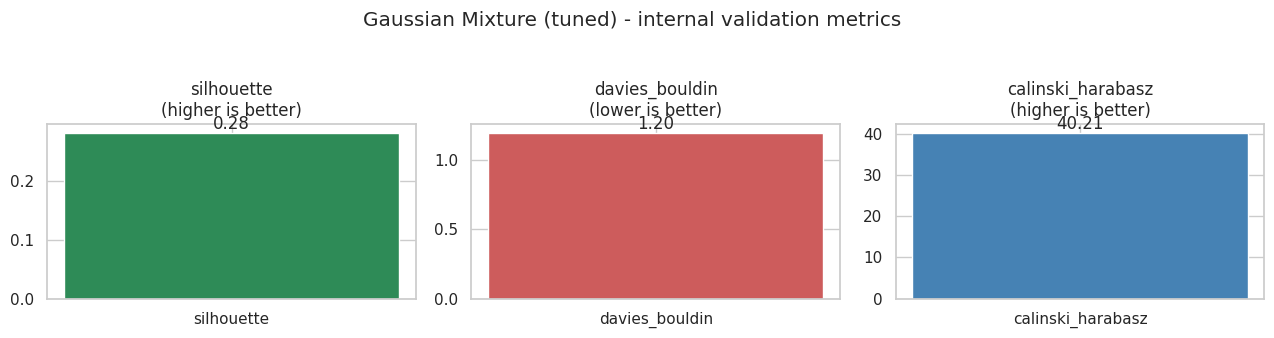

In [67]:
# ML Model - 3 with hyperparameter optimisation (grid over components x covariance type, BIC + silhouette)
rows = []
for cov in ['full', 'tied', 'diag', 'spherical']:
    for k in range(MIN_K, 9):
        g = GaussianMixture(n_components=k, covariance_type=cov, n_init=5, random_state=RANDOM_STATE).fit(X_scaled)
        lab = g.predict(X_scaled)
        if is_valid(lab):
            rows.append({'covariance': cov, 'k': k, 'bic': g.bic(X_scaled), **score_labels(X_scaled, lab)})
gmm_grid = pd.DataFrame(rows).sort_values('silhouette', ascending=False)
display(gmm_grid.head(5).round(3))
bg = gmm_grid.iloc[0]
gmm2 = GaussianMixture(n_components=int(bg['k']), covariance_type=bg['covariance'], n_init=5, random_state=RANDOM_STATE).fit(X_scaled)
gmm2_labels = gmm2.predict(X_scaled)
gmm2_scores = score_labels(X_scaled, gmm2_labels)
print("Tuned GMM ->", {k: round(v, 3) for k, v in gmm2_scores.items()}, "| covariance =", bg['covariance'], "| k =", int(bg['k']))
plot_scores(gmm2_scores, 'Gaussian Mixture (tuned) - internal validation metrics')

##### Which hyperparameter optimization technique have you used and why?
Grid search over the covariance type (full / tied / diag / spherical) and number of components (3-8) with 5 initialisations each, evaluated with silhouette (and BIC for reference) because BIC alone tends to choose more components than are actionable.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.
**Yes, a clear improvement:** the tuned GMM uses a *spherical* covariance, which has far fewer parameters than the baseline *full* covariance (an over-parameterised model for 100 points). Silhouette rises from **0.219 to 0.282**, Davies-Bouldin improves from **1.494 to 1.196** and Calinski-Harabasz from **26.5 to 40.2**.

### Comparing all models and selecting the final one

,silhouette,davies_bouldin,calinski_harabasz,k,smallest_cluster_%
K-Means (baseline),0.277,1.221,41.059,3.0,15.0
K-Means (tuned),0.277,1.221,41.059,3.0,15.0
Hierarchical (baseline),0.262,1.286,38.328,3.0,18.0
Hierarchical (tuned),0.262,1.286,38.328,3.0,18.0
GMM (baseline),0.219,1.494,26.475,3.0,15.0
GMM (tuned),0.282,1.196,40.208,3.0,13.0


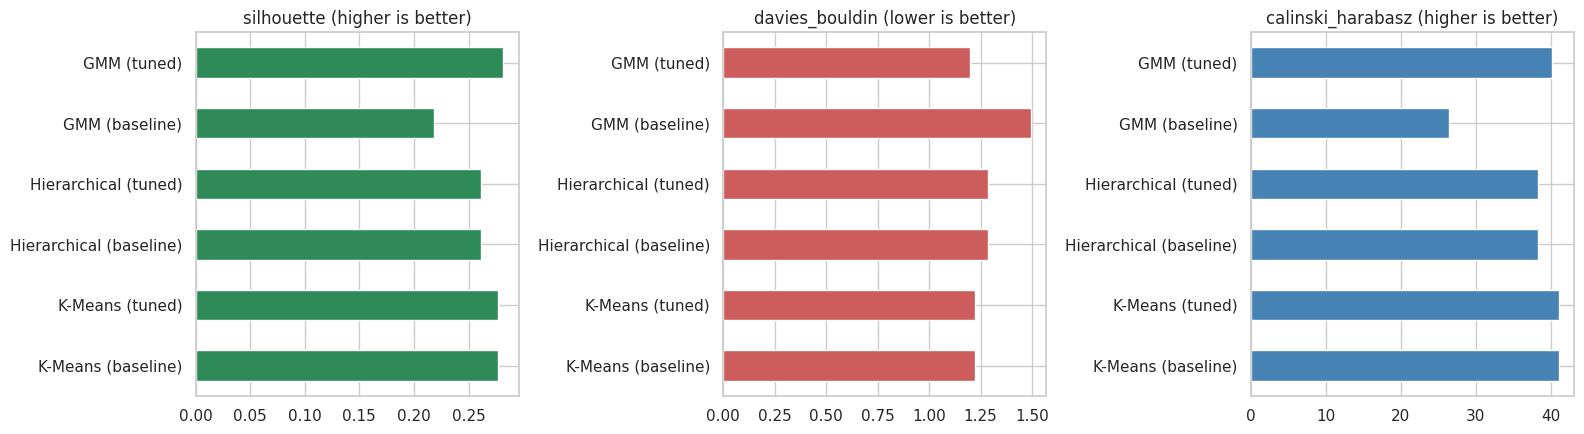

In [68]:
# Compare all models
labels_by_model = {'K-Means (baseline)': km1_labels, 'K-Means (tuned)': km2_labels, 'Hierarchical (baseline)': hc1_labels,
                   'Hierarchical (tuned)': hc2_labels, 'GMM (baseline)': gmm1_labels, 'GMM (tuned)': gmm2_labels}
comparison = pd.DataFrame({
    'K-Means (baseline)': {**km1_scores, 'k': K_BASE}, 'K-Means (tuned)': {**km2_scores, 'k': km2.n_clusters},
    'Hierarchical (baseline)': {**hc1_scores, 'k': K_BASE}, 'Hierarchical (tuned)': {**hc2_scores, 'k': int(bh['k'])},
    'GMM (baseline)': {**gmm1_scores, 'k': K_BASE}, 'GMM (tuned)': {**gmm2_scores, 'k': int(bg['k'])}}).T
comparison['smallest_cluster_%'] = [pd.Series(l).value_counts(normalize=True).min() * 100 for l in labels_by_model.values()]
display(comparison.round(3))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, metric, col in zip(axes, ['silhouette', 'davies_bouldin', 'calinski_harabasz'], ['seagreen', 'indianred', 'steelblue']):
    comparison[metric].plot(kind='barh', ax=ax, color=col); ax.set_title(metric + (' (lower is better)' if metric == 'davies_bouldin' else ' (higher is better)'))
plt.tight_layout(); plt.show()

In [69]:
# Final model selection: best silhouette among valid segmentations (ties go to the tuned model, listed last)
valid_models = [n for n, l in labels_by_model.items() if is_valid(l)]
FINAL_NAME = comparison.loc[valid_models, 'silhouette'].round(4)[::-1].idxmax()
print("Selected final model:", FINAL_NAME)
raw_labels = pd.Series(labels_by_model[FINAL_NAME])
# Re-number clusters so that 0 = best-rated segment ... 2 = lowest-rated segment (algorithms number clusters arbitrarily)
order = rest_model.assign(raw=raw_labels).groupby('raw')['avg_rating'].mean().sort_values(ascending=False).index
rank = {old: new for new, old in enumerate(order)}
rest_model['cluster'] = raw_labels.map(rank).values
SEGMENT_NAMES = {0: 'Premium crowd-pleasers', 1: 'Buzzy mid-premium', 2: 'Budget quick-service'}   # names chosen after profiling (see below)
rest_model['segment'] = rest_model['cluster'].map(SEGMENT_NAMES)
print(rest_model['segment'].value_counts())
print("Agreement (ARI) between the final model and K-Means (tuned):", round(adjusted_rand_score(labels_by_model[FINAL_NAME], km2_labels), 3))

Selected final model: GMM (tuned)
segment
Budget quick-service      53
Buzzy mid-premium         34
Premium crowd-pleasers    13
Name: count, dtype: int64
Agreement (ARI) between the final model and K-Means (tuned): 0.762


#### 3. Explain each evaluation metric's indication towards business and the business impact of the ML model used.
* **Silhouette (0.28):** how much closer a restaurant is to its own segment than to the next one. A value of 0.28 indicates a real but *overlapping* structure - restaurants form tiers of a continuum (price/quality) rather than isolated islands. For the business, this means segment labels are good for broad strategy, while restaurants near the borders need individual judgement.
* **Davies-Bouldin (1.20, lower is better):** the average similarity between each segment and its closest neighbour. A value near 1 means segments are reasonably compact and distinct, so a campaign designed for one segment will not be wasted on another.
* **Calinski-Harabasz (40, higher is better):** ratio of between-segment to within-segment variance - high values confirm that the segments differ strongly on price, rating and reviewer engagement, supporting different tactics per segment.
* **Bootstrap stability (ARI 0.76):** the same three segments are recovered after resampling, so the strategy will not change every time the data are refreshed.
* **Business impact:** instead of treating 100 restaurants one by one, Zomato manages three segments, with a targeted playbook each (see the strategy section below), reducing the effort for account managers and marketing.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?
Silhouette and Davies-Bouldin (cluster quality and separation) were the main criteria, backed by Calinski-Harabasz and bootstrap stability (reliability when data change). The segments additionally had to be *actionable*: at least 3 segments and none smaller than 10% of restaurants, so that each can receive its own campaign.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?
**Gaussian Mixture (spherical covariance, k = 3)**: best silhouette (0.282) and best Davies-Bouldin (1.196) with a healthy minimum segment size (13%). It also provides soft probabilities for borderline restaurants. In fairness, K-Means is a very close runner-up (silhouette 0.277, best Calinski-Harabasz 41.1) and the two agree on most restaurants (Adjusted Rand Index 0.76); K-Means could be used as a simpler alternative with practically identical business conclusions. All three algorithms recover the same three-tier structure, which strengthens confidence in the result.

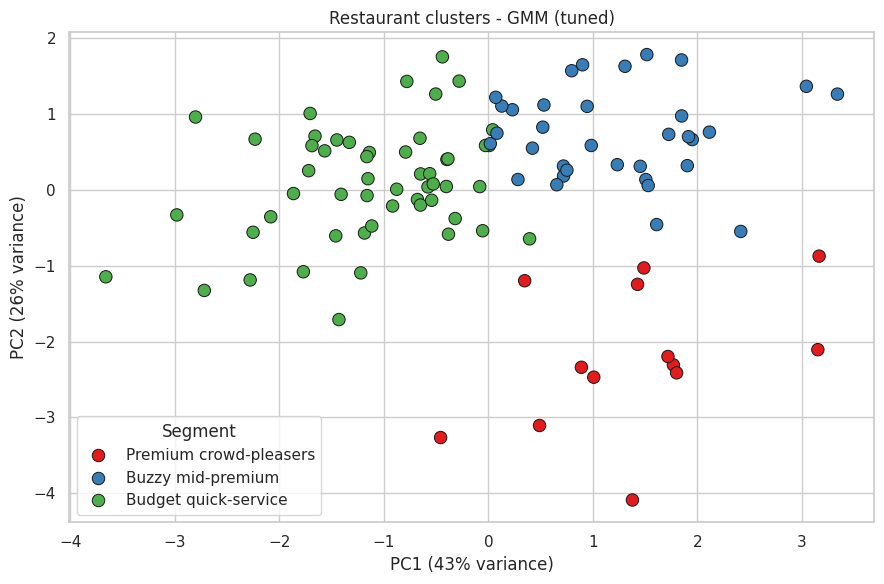

In [70]:
# Visualise the final clusters in 2-D (PCA projection of the scaled features)
plt.figure(figsize=(9, 6))
sns.scatterplot(x=X_pca2[:, 0], y=X_pca2[:, 1], hue=rest_model['segment'], hue_order=list(SEGMENT_NAMES.values()), palette='Set1', s=80, edgecolor='k')
plt.xlabel(f'PC1 ({pca2.explained_variance_ratio_[0]:.0%} variance)'); plt.ylabel(f'PC2 ({pca2.explained_variance_ratio_[1]:.0%} variance)')
plt.title(f'Restaurant clusters - {FINAL_NAME}'); plt.legend(title='Segment')
plt.tight_layout(); plt.show()

,restaurants,Cost,avg_rating,avg_sentiment,pct_negative,avg_followers,avg_review_len,avg_pictures,n_cuisines,n_collections,open_hours
0 - Premium crowd-pleasers,13,1353.85,4.34,0.63,0.10,74.48,49.97,0.53,3.77,3.54,10.35
1 - Buzzy mid-premium,34,1194.12,3.70,0.36,0.19,252.96,72.69,1.51,3.29,1.15,11.23
2 - Budget quick-service,53,547.17,3.36,0.15,0.32,127.94,36.02,0.34,2.64,0.38,12.24


,cuisine_north_indian,cuisine_chinese,cuisine_continental,cuisine_biryani,cuisine_asian,cuisine_fast_food
cluster,,,,,,
0,0.77,0.31,0.38,0.08,0.38,0.00
1,0.56,0.41,0.32,0.00,0.21,0.09
2,0.58,0.43,0.09,0.26,0.04,0.19


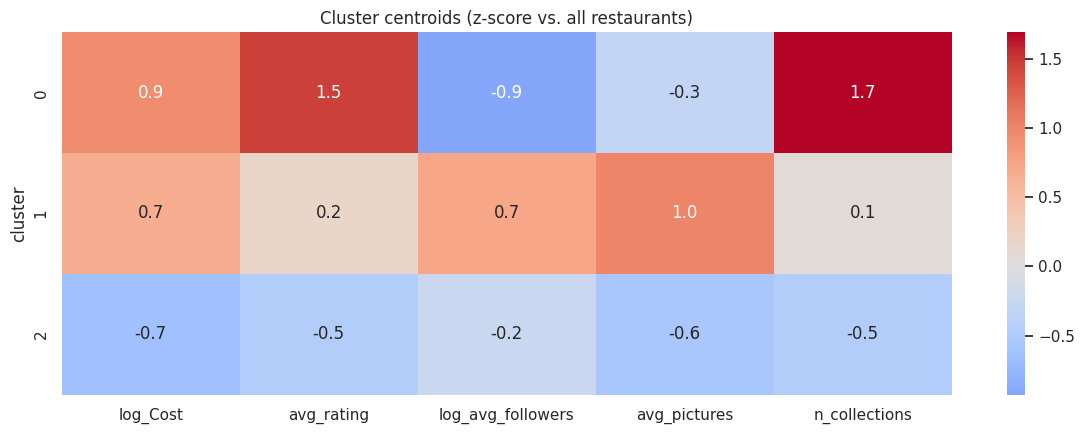

Cluster 0 (Premium crowd-pleasers): ['Beyond Flavours', 'Paradise', 'Flechazo', 'Over The Moon Brew Company', "The Fisherman's Wharf", 'The Lal Street - Bar Exchange']
Cluster 1 (Buzzy mid-premium): ['Hyper Local', 'Barbeque Nation', '10 Downing Street', "Jonathan's Kitchen - Holiday Inn Express & Suites", 'Pista House', 'Marsala Food Company']
Cluster 2 (Budget quick-service): ['Shah Ghouse Hotel & Restaurant', 'eat.fit', 'Shah Ghouse Spl Shawarma', 'Cream Stone', "Sardarji's Chaats & More", 'Absolute Sizzlers']


In [71]:
# Cluster profiles (original units) - what does each segment look like?
prof_cols = ['Cost', 'avg_rating', 'avg_sentiment', 'pct_negative', 'avg_followers', 'avg_review_len', 'avg_pictures',
             'n_cuisines', 'n_collections', 'open_hours']
profile = rest_model.groupby('cluster')[prof_cols].mean().round(2)
profile.insert(0, 'restaurants', rest_model['cluster'].value_counts().sort_index())
profile.index = [f'{c} - {SEGMENT_NAMES[c]}' for c in profile.index]
display(profile)
cuisine_cols = list(cuisine_flags.columns)
cuisine_share = rest_model.groupby('cluster')[cuisine_cols].mean().round(2)
display(cuisine_share)
plt.figure(figsize=(12, 4.5))
z = rest_model.groupby('cluster')[FEATURES].mean()
z = (z - rest_model[FEATURES].mean()) / rest_model[FEATURES].std()
sns.heatmap(z, annot=True, fmt='.1f', cmap='coolwarm', center=0)
plt.title('Cluster centroids (z-score vs. all restaurants)'); plt.tight_layout(); plt.show()
for c in sorted(rest_model['cluster'].unique()):
    names = rest_model.loc[rest_model['cluster'] == c].sort_values('n_reviews', ascending=False)['Name'].head(6).tolist()
    print(f"Cluster {c} ({SEGMENT_NAMES[c]}): {names}")

**Segment names (based on the profile table):**

| Segment | Restaurants | Typical cost for two | Avg rating | Negative reviews | Distinguishing traits |
|---|---|---|---|---|---|
| **Premium crowd-pleasers** | 13 | about Rs 1,350 | 4.34 | 10% | highest rating and sentiment, most consistent ratings, 3.5 Zomato collections, 3.8 cuisines (North Indian, Asian, Continental); e.g. AB's Absolute Barbecues, B-Dubs, Paradise, Flechazo |
| **Buzzy mid-premium** | 34 | about Rs 1,190 | 3.70 | 19% | most engaged reviewers (avg 253 followers), longest reviews (73 words), most pictures per review (1.5), few collections (1.15) |
| **Budget quick-service** | 53 | about Rs 550 | 3.36 | 32% | lowest rating and highest share of negative reviews, shortest reviews, almost no collections (0.38), longest opening hours (12.2 h), Biryani / Fast Food / Chinese |

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

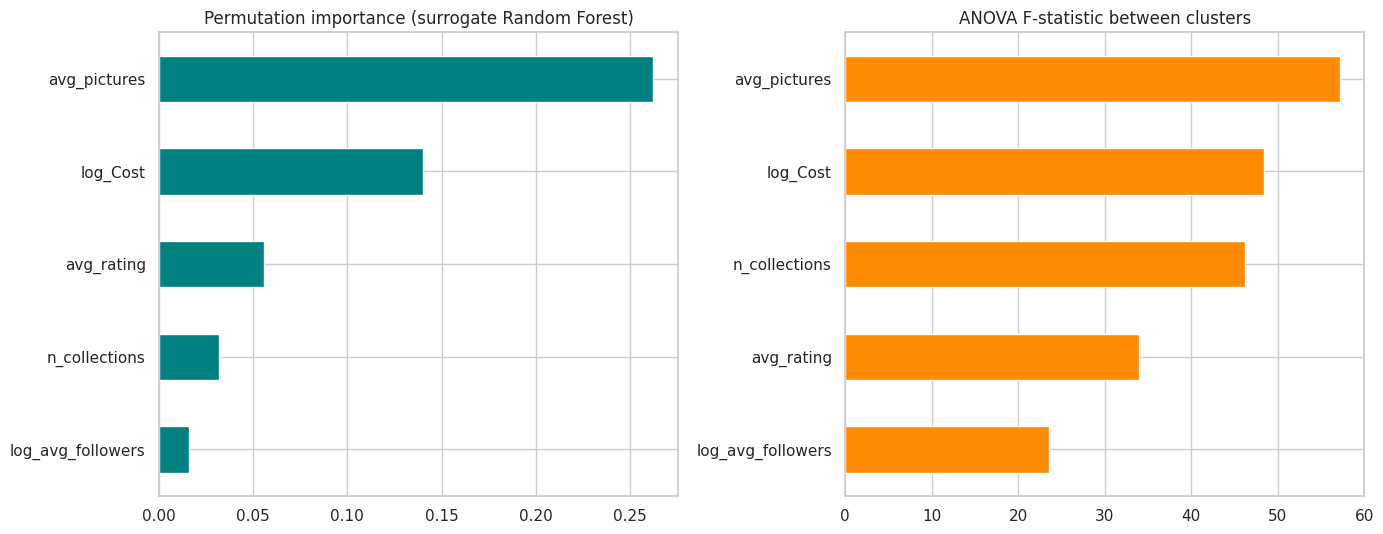

Top 5 separating features: ['avg_pictures', 'log_Cost', 'avg_rating', 'n_collections', 'log_avg_followers']


In [72]:
# Model explainability: which features separate the clusters?  (surrogate Random Forest + permutation importance + ANOVA F)
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE).fit(X_scaled, rest_model['cluster'])
perm = permutation_importance(rf, X_scaled, rest_model['cluster'], n_repeats=20, random_state=RANDOM_STATE)
imp = pd.Series(perm.importances_mean, index=FEATURES).sort_values()
f_vals = pd.Series({f: stats.f_oneway(*[g[f].values for _, g in rest_model.groupby('cluster')])[0] for f in FEATURES}).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
imp.plot(kind='barh', ax=axes[0], color='teal'); axes[0].set_title('Permutation importance (surrogate Random Forest)')
f_vals.plot(kind='barh', ax=axes[1], color='darkorange'); axes[1].set_title('ANOVA F-statistic between clusters')
plt.tight_layout(); plt.show()
print("Top 5 separating features:", list(imp.sort_values(ascending=False).head(5).index))

The final GMM is a probabilistic model, so to explain it we trained a **surrogate Random Forest** that predicts the cluster from the features and measured **permutation importance**, supported by the **ANOVA F-statistic** between clusters and the **centroid heatmap** above. Result: **pictures per review (0.26)** and **cost (0.14)** separate the segments most, followed by average rating (0.06), number of collections (0.03) and reviewer followers (0.02). In other words, the segments are mainly defined by *price tier* and *how engaged the review audience is*, and the rating then confirms the quality gap. SHAP can be used in the same way when the library is available, but permutation importance needs no extra installation.

### Brief strategy for each segment

**1. Premium crowd-pleasers (13 restaurants - protect and promote).** Highest ratings and most consistent feedback. Feature them in 'Top-Rated', 'Great Buffets' and 'Hyderabad's Hottest' collections, offer Gold / group-dining promotions and reservation tools, and use them as quality benchmarks for the rest of the platform. Watch peak-hour service, because 10 pm weekend rushes can hurt the experience.

**2. Buzzy mid-premium (34 restaurants - fix consistency while in the spotlight).** They attract the most influential, detail-oriented reviewers (long, photo-rich reviews) but only a 3.70 average rating and 19% negative reviews, and they are rarely tagged in collections. Prioritise service recovery for high-follower reviewers, reply to reviews, fix the recurring taste/service complaints seen in the word analysis, and then add collection tags to convert visibility into bookings.

**3. Budget quick-service (53 restaurants - volume business that needs quality and visibility).** More than half of the restaurants, with the lowest ratings and 32% negative reviews. Focus on hygiene/food-quality audits, delivery-time and packaging standards, value combos around Rs 500, 'late night' / 'veggie friendly' tags, and encouraging customers to upload photos. Restaurants below 3 stars should receive an improvement plan before they churn.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

In [73]:
# Save the File - scaler + final deployable model + feature list in one bundle
# Hierarchical clustering has no predict() for unseen data, so if it wins we deploy a K-Means refit instead.
fitted = {'K-Means (baseline)': km1, 'K-Means (tuned)': km2, 'GMM (baseline)': gmm1, 'GMM (tuned)': gmm2}
deploy_model = fitted.get(FINAL_NAME, KMeans(n_clusters=int(rest_model['cluster'].nunique()), n_init=30, random_state=RANDOM_STATE).fit(X_scaled))
raw_pred = deploy_model.predict(X_scaled)
label_map = pd.crosstab(raw_pred, rest_model['cluster']).idxmax(axis=1).to_dict()      # raw model label -> ordered segment id
bundle = {'scaler': scaler, 'model': deploy_model, 'features': FEATURES, 'label_map': label_map, 'segment_names': SEGMENT_NAMES}
joblib.dump(bundle, 'zomato_cluster_model.joblib')
print("Saved zomato_cluster_model.joblib | agreement with final clusters (ARI):", round(adjusted_rand_score(rest_model['cluster'], raw_pred), 3))

Saved zomato_cluster_model.joblib | agreement with final clusters (ARI): 1.0


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.

In [74]:
# Load the File and predict unseen data.
loaded = joblib.load('zomato_cluster_model.joblib')
# Sanity check 1: a brand-new (made-up) premium restaurant - Rs 1500 for two, 4.4 rating, 3 Zomato collections, few followers, few photos
new_restaurant = pd.DataFrame([{'log_Cost': np.log1p(1500), 'avg_rating': 4.4, 'log_avg_followers': np.log1p(60),
                                'avg_pictures': 0.5, 'n_collections': 3}])[loaded['features']]
seg = loaded['label_map'][int(loaded['model'].predict(loaded['scaler'].transform(new_restaurant))[0])]
print("New premium-style restaurant ->", loaded['segment_names'][seg])
# Sanity check 2: a new cheap, low-rated, hardly-curated outlet
cheap = pd.DataFrame([{'log_Cost': np.log1p(300), 'avg_rating': 3.0, 'log_avg_followers': np.log1p(100),
                       'avg_pictures': 0.2, 'n_collections': 0}])[loaded['features']]
seg2 = loaded['label_map'][int(loaded['model'].predict(loaded['scaler'].transform(cheap))[0])]
print("New budget-style restaurant  ->", loaded['segment_names'][seg2])

New premium-style restaurant -> Premium crowd-pleasers
New budget-style restaurant  -> Budget quick-service


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

* **Data:** 105 Hyderabad restaurants and 10,000 reviews were cleaned (36 duplicates and 38 unrated rows removed, costs, reviewer metadata and timings parsed) and 100 restaurants with reviews were analysed.
* **Customer behaviour:** ratings are polarised (63% 4-5 stars, 24% 1-2 stars); cost is moderately and significantly correlated with rating (rho = 0.38); reviews with pictures are rated higher (3.86 vs 3.54); reviewer influence is concentrated in a small group of highly-followed users; reviews peak on weekends and around 9-11 pm; *service*, *taste* and negations ('not') dominate the language of negative reviews.
* **Sentiment:** a TF-IDF + Logistic Regression model (80% hold-out accuracy) gives restaurant sentiment scores that agree with star ratings (r = 0.97).
* **Clustering:** K-Means, Hierarchical and Gaussian Mixture all find three segments; the tuned Gaussian Mixture is the final model (silhouette 0.282, Davies-Bouldin 1.196, Calinski-Harabasz 40.2, bootstrap stability ARI about 0.76 for the K-Means equivalent). The segments are **Premium crowd-pleasers (13), Buzzy mid-premium (34) and Budget quick-service (53)**, defined mainly by price tier, review engagement and rating.
* **How the stakeholders can use it:** *Zomato* can target promotions, collection placement, onboarding of under-served cuisines and quality-improvement programmes by segment; *restaurant owners* can benchmark themselves against their segment, see which themes drive their negative reviews, and know when to invest in service recovery; *customers* get better recommendations because restaurants are grouped by true price-quality experience.
* **Limitations and next steps:** one city; exactly 100 reviews per restaurant (a sample, so volume trends are not reliable); only 100 clustering data points and moderate silhouette values (overlapping tiers); sentiment is learned from star ratings (a proxy). Next steps: add delivery / location / order-volume data, test a transformer-based sentiment model, and refit the segments regularly with fresh reviews.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***